# 11 · Classification Algorithms — Complete Reference

Classification is the task of learning a mapping from a feature vector
$x \in \mathbb{R}^d$ to a *discrete* label $y$. This notebook is the
one-stop revision sheet for the DSMP classification arc: how to **evaluate**
a classifier (confusion matrix, precision/recall/F1, ROC-AUC, PR curves),
and the four families of models covered in the course — **KNN, Naive Bayes,
Logistic/Softmax Regression and SVM** — from the maths down to runnable
scikit-learn code, plus from-scratch NumPy implementations.

Everything below runs top-to-bottom in a fresh kernel (scikit-learn 1.7,
no internet, all randomness seeded with `random_state=42`).

**How this maps to the playlist:** sections 2–3 = evaluation sessions,
sections 4–5 = KNN + Naive Bayes, section 6 = MLE (the engine behind
logistic regression), sections 7–8 = logistic & softmax,
sections 9–10 = the two SVM sessions, section 11 = a mini project that puts
all five models on one dataset.

## ▶ Sessions covered

| # | Session | Video |
|---|---------|-------|
| 166 | What is K Nearest Neighbors? | https://www.youtube.com/watch?v=abnL_GUGub4 |
| 168 | Session on Advanced KNN | https://www.youtube.com/watch?v=d7xo69q-1H4 |
| 176 | Accuracy, Confusion Matrix, Type 1 & Type 2 Errors | https://www.youtube.com/watch?v=c09drtuCS3c |
| 177 | Precision, Recall and F1 Score | https://www.youtube.com/watch?v=iK-kdhJ-7yI |
| 185 | ROC Curve and AUC | https://www.youtube.com/watch?v=gdW6hj9IXaA |
| 192 | Session 1 on Naive Bayes | https://www.youtube.com/watch?v=mEjGU4e-WPs |
| 191 | Session 2 on Naive Bayes | https://www.youtube.com/watch?v=mrBut7CPCxE |
| 193 | Session 3 on Naive Bayes | https://www.youtube.com/watch?v=_x61Lut84zI |
| 194 | Session 1 on Logistic Regression | https://www.youtube.com/watch?v=BuAp03q5GAw |
| 197 | Session 3 on Logistic Regression | https://www.youtube.com/watch?v=u2IfZX5q2jY |
| 196 | Session on Maximum Likelihood Estimation | https://www.youtube.com/watch?v=YSur3ESoV_U |
| 195 | Session on Softmax Regression (Multiclass) | https://www.youtube.com/watch?v=Dg-1TuPxElw |
| 198 | SVM Part 1 \| Hard Margin SVM | https://www.youtube.com/watch?v=HfrKYccB2DQ |
| 200 | SVM Part 2 \| Soft Margin SVM | https://www.youtube.com/watch?v=SlsXm-utgFY |

In [1]:
%matplotlib inline
import warnings

# NOTE: environment quirk — this macOS/Accelerate BLAS build emits spurious
# "… encountered in matmul" RuntimeWarnings for float64 `@` on large arrays
# even when every input is finite (the result was verified bit-identical to
# np.einsum). Keep the filter narrow so real numpy warnings still surface.
warnings.filterwarnings("ignore", message=r".* encountered in matmul")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from sklearn.datasets import make_classification, make_moons, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    log_loss,
)
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC, SVR
from sklearn.feature_extraction.text import CountVectorizer

SEED = 42
np.random.seed(SEED)  # legacy global seed (modern estimators use random_state=SEED)

print("numpy", np.__version__, "| pandas", pd.__version__)
print("sklearn ready — all randomness fixed at random_state =", SEED)


numpy 2.2.6 | pandas 2.3.3
sklearn ready — all randomness fixed at random_state = 42


---
## 1. Classification fundamentals

▶ #166 What is K Nearest Neighbors?: https://www.youtube.com/watch?v=abnL_GUGub4
▶ #176 Accuracy, Confusion Matrix, Type 1 & Type 2 Errors: https://www.youtube.com/watch?v=c09drtuCS3c

**Binary vs multiclass**

| Setting | # classes | Example | Typical model shape |
|---|---|---|---|
| Binary | 2 (usually encoded 0/1) | spam / not-spam | one decision function |
| Multiclass | 3+ | cat / dog / bird | K binary models (OvR) **or** one K-way softmax |
| Multilabel | 2+ *per row* (out of scope here) | movie tags | K independent sigmoids |

**Decision boundary** — the surface in feature space where the model switches
from predicting class 0 to class 1. Linear models give a hyperplane
$w\cdot x + b = 0$; KNN/Naive Bayes/SVM-with-kernels give curved boundaries.
Plotting it (we do this a lot below) is the fastest way to *see* underfitting
(boundary too simple) vs overfitting (wiggly and data-specific).

**Probabilistic vs deterministic classifiers**

| Type | What it outputs | Members |
|---|---|---|
| Probabilistic | $P(y \mid x)$ (rows sum to 1) | Logistic/Softmax, Naive Bayes, KNN (vote fractions), SVM with `probability=True` |
| Deterministic | only a hard label | plain SVM (`decision_function` sign), perceptron |

Probabilities let you **move the threshold** and score with log loss; hard-label
models can only be judged with accuracy / precision / recall / F1.

**The 0.5 threshold** — a probabilistic binary classifier predicts
`class 1 if P(1|x) >= t`, default `t = 0.5`. It is a *business knob*, not a
law of nature:

- lower `t` (0.3) → more rows predicted positive → **recall ↑, precision ↓**
- higher `t` (0.7) → fewer positives → **precision ↑, recall ↓**

Tune `t` on a validation set, never on the test set (demo in §7).

> **Gotcha:** the threshold that maximises *accuracy* is usually the wrong
> threshold — it ignores the cost asymmetry between FP and FN.

In [2]:
# --- four seeded datasets reused by the whole notebook ----------------------
# 1. binary, roughly linearly separable (metrics, ROC, logistic regression)
X_bin, y_bin = make_classification(
    n_samples=600, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.4, flip_y=0.05, random_state=SEED,
)

# 2. two interleaving half-moons (KNN, SVM kernels, model comparison)
X_moon, y_moon = make_moons(n_samples=600, noise=0.25, random_state=SEED)

# 3. three classes, 2-D so we can draw the decision regions
X_multi, y_multi = make_classification(
    n_samples=600, n_features=2, n_informative=2, n_redundant=0,
    n_classes=3, n_clusters_per_class=1, class_sep=1.6, flip_y=0.05,
    random_state=SEED,
)

# 4. imbalanced: exactly 95% class 0 / 5% class 1 (accuracy-lies demo, §2/§3)
X_imb, y_imb = make_classification(
    n_samples=1000, n_features=10, n_informative=6, n_redundant=2,
    weights=[0.95, 0.05], flip_y=0.0, random_state=SEED,
)


def describe(name, X, y):
    cls, cnt = np.unique(y, return_counts=True)
    cls = [int(c) for c in cls]
    cnt = [int(c) for c in cnt]
    frac = {c: round(k / sum(cnt), 3) for c, k in zip(cls, cnt)}
    print(f"{name:9s} X{str(X.shape):11s} classes {dict(zip(cls, cnt))}  frac {frac}")


describe("binary", X_bin, y_bin)
describe("moons", X_moon, y_moon)
describe("multi", X_multi, y_multi)
describe("imbal", X_imb, y_imb)

# stratified train/test splits — every section reuses these (75/25)
SPLIT = dict(test_size=0.25, random_state=SEED)
X_tr, X_te, y_tr, y_te = train_test_split(X_bin, y_bin, stratify=y_bin, **SPLIT)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(X_moon, y_moon, stratify=y_moon, **SPLIT)
Xu_tr, Xu_te, yu_tr, yu_te = train_test_split(X_multi, y_multi, stratify=y_multi, **SPLIT)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(X_imb, y_imb, stratify=y_imb, **SPLIT)

print("\nshapes -> binary", X_tr.shape, X_te.shape, "| moons",
      Xm_tr.shape, Xm_te.shape, "| multiclass", Xu_tr.shape, Xu_te.shape,
      "| imbalanced", Xi_tr.shape, Xi_te.shape)


binary    X(600, 2)    classes {0: 301, 1: 299}  frac {0: 0.502, 1: 0.498}
moons     X(600, 2)    classes {0: 300, 1: 300}  frac {0: 0.5, 1: 0.5}
multi     X(600, 2)    classes {0: 200, 1: 195, 2: 205}  frac {0: 0.333, 1: 0.325, 2: 0.342}
imbal     X(1000, 10)  classes {0: 950, 1: 50}  frac {0: 0.95, 1: 0.05}

shapes -> binary (450, 2) (150, 2) | moons (450, 2) (150, 2) | multiclass (450, 2) (150, 2) | imbalanced (750, 10) (250, 10)


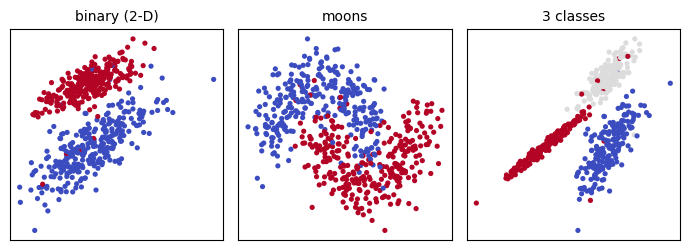

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(7, 2.6))
sets = [(X_bin, y_bin, "binary (2-D)"), (X_moon, y_moon, "moons"),
        (X_multi, y_multi, "3 classes")]
for ax, (X, y, t) in zip(axes, sets):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=14, edgecolors="none")
    ax.set_title(t, fontsize=10)
    ax.set_xticks([]), ax.set_yticks([])
plt.tight_layout()
plt.show()


**Section notes — fundamentals:**

| Idea | One-liner |
|---|---|
| binary vs multiclass | 2 labels vs K labels; multiclass = OvR or softmax |
| decision boundary | surface where the predicted class flips |
| probabilistic model | outputs $P(y\mid x)$ → the threshold is tunable |
| default threshold | 0.5; lower ⇒ recall↑ precision↓ |
| imbalance | a 95/5 split breaks accuracy — see §2 |

> **TIP:** always split **stratified** (`stratify=y`) so the 5% minority
> class survives into both train and test sets.

---
## 2. Evaluation metrics — confusion matrix

▶ #176 Accuracy, Confusion Matrix, Type 1 & Type 2 Errors: https://www.youtube.com/watch?v=c09drtuCS3c
▶ #177 Precision, Recall and F1 Score: https://www.youtube.com/watch?v=iK-kdhJ-7yI

### The 2×2 layout

| | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | TN (correct reject) | FP (**Type I error**) |
| **Actual 1** | FN (**Type II error**) | TP (correct hit) |

`sklearn` returns exactly this matrix: `confusion_matrix(y, pred) =
[[TN, FP], [FN, TP]]` (rows = truth, cols = prediction).

### Type I vs Type II errors in the real world

| Domain | "H0 = normal" | Type I (false **positive**) | Type II (false **negative**) |
|---|---|---|---|
| Spam filter | mail is legitimate | a real mail lands in Spam | a spam mail reaches the inbox |
| Disease test | patient is healthy | healthy person told "sick" (extra tests) | **sick person told "healthy" (dangerous)** |
| Fraud check | transaction is genuine | genuine payment blocked | fraud goes unnoticed |
| Loan approval | applicant will repay | good applicant rejected (lost business) | defaulter given a loan (money lost) |

Rule of thumb: **Type I = "crying wolf", Type II = "missing the wolf".**
Which one costs more is a business decision — it decides whether you optimise
precision or recall.

### The formulas

$$\text{accuracy} = \frac{TP+TN}{TP+TN+FP+FN} \qquad
\text{precision} = \frac{TP}{TP+FP} \qquad
\text{recall} = \frac{TP}{TP+FN} \qquad
F_1 = 2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

confusion matrix [[TN, FP], [FN, TP]] =
 [[72  3]
 [ 2 73]]
TN=72  FP=3  FN=2  TP=73

accuracy  manual : 0.9666666666666667 | sklearn: 0.9666666666666667
precision manual : 0.9605263157894737 | sklearn: 0.9605263157894737
recall    manual : 0.9733333333333334 | sklearn: 0.9733333333333334
f1        manual : 0.9668874172185431 | sklearn: 0.9668874172185431


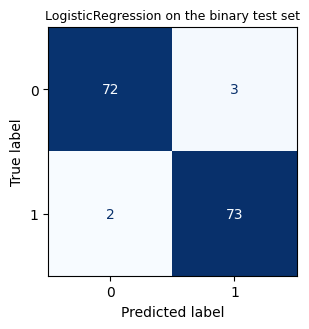

In [4]:
scaler = StandardScaler().fit(X_tr)
logit = LogisticRegression(max_iter=500, random_state=SEED).fit(scaler.transform(X_tr), y_tr)
pred = logit.predict(scaler.transform(X_te))

cm = confusion_matrix(y_te, pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("confusion matrix [[TN, FP], [FN, TP]] =\n", cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

print("\naccuracy  manual :", (tp + tn) / len(y_te), "| sklearn:", accuracy_score(y_te, pred))
print("precision manual :", tp / (tp + fp), "| sklearn:", precision_score(y_te, pred))
print("recall    manual :", tp / (tp + fn), "| sklearn:", recall_score(y_te, pred))
print("f1        manual :", 2 * tp / (2 * tp + fp + fn), "| sklearn:", f1_score(y_te, pred))
# NOTE: F1 with counts only is 2TP / (2TP + FP + FN) — P and R never needed.

fig, ax = plt.subplots(figsize=(4.2, 3.4))
ConfusionMatrixDisplay.from_estimator(
    logit, scaler.transform(X_te), y_te, ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("LogisticRegression on the binary test set", fontsize=9)
plt.tight_layout()
plt.show()


### When accuracy lies

On a **95 / 5** imbalanced dataset a model that answers "class 0" for every
row scores **95 % accuracy** while being useless. Below: the dummy baseline
vs a real learner on the same split.

In [5]:
cls_tr, cnt_tr = np.unique(yi_tr, return_counts=True)
print("class balance (train):", {int(c): int(n) for c, n in zip(cls_tr, cnt_tr)})

dummy = DummyClassifier(strategy="most_frequent").fit(Xi_tr, yi_tr)
real = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)
).fit(Xi_tr, yi_tr)

rows = []
for name, model in [("Dummy (always class 0)", dummy), ("LogisticRegression", real)]:
    p = model.predict(Xi_te)
    rows.append(dict(
        model=name,
        accuracy=accuracy_score(yi_te, p),
        precision=precision_score(yi_te, p, zero_division=0),
        recall=recall_score(yi_te, p, zero_division=0),
        f1=f1_score(yi_te, p, zero_division=0),
        balanced_acc=balanced_accuracy_score(yi_te, p),
    ))
    print(f"\n--- {name} ---")
    print(confusion_matrix(yi_te, p))
    print(classification_report(yi_te, p, digits=3, zero_division=0))

print(pd.DataFrame(rows).set_index("model").round(4))
# NOTE: dummy accuracy ≈ 0.95 but recall on the minority class is exactly 0.
# TIP: balanced accuracy = mean of per-class recalls; it exposes that failure.


class balance (train): {0: 712, 1: 38}

--- Dummy (always class 0) ---
[[238   0]
 [ 12   0]]
              precision    recall  f1-score   support

           0      0.952     1.000     0.975       238
           1      0.000     0.000     0.000        12

    accuracy                          0.952       250
   macro avg      0.476     0.500     0.488       250
weighted avg      0.906     0.952     0.929       250


--- LogisticRegression ---
[[235   3]
 [ 10   2]]
              precision    recall  f1-score   support

           0      0.959     0.987     0.973       238
           1      0.400     0.167     0.235        12

    accuracy                          0.948       250
   macro avg      0.680     0.577     0.604       250
weighted avg      0.932     0.948     0.938       250

                        accuracy  precision  recall      f1  balanced_acc
model                                                                    
Dummy (always class 0)     0.952        0.0  0.0000  

### `classification_report()` — reading every column

**What it does:** one call → precision / recall / f1 / support per class, plus
macro, weighted and accuracy rows.
**Syntax:** `classification_report(y_true, y_pred, labels=None, target_names=None, digits=2, output_dict=False, zero_division='warn')`
**Parameters:**
- `y_true`, `y_pred` — array-likes of the same length
- `labels` — which classes to include (and in which order)
- `output_dict` — return a `dict` instead of a string (pipe into `pd.DataFrame`)
- `zero_division` — value reported when a denominator is 0 (`0`, `1`, `warn`)
**Returns:** `str` (pretty table) or `dict`

In [6]:
best_model = LogisticRegression(max_iter=500, random_state=SEED).fit(Xu_tr, yu_tr)
yu_pred = best_model.predict(Xu_te)

print(classification_report(yu_te, yu_pred, digits=3, zero_division=0))

rep = classification_report(yu_te, yu_pred, output_dict=True, zero_division=0)
print(pd.DataFrame(rep).T.round(3))
print("\nmacro avg   = UNWEIGHTED mean over classes -> every class counts equally")
print("weighted avg = support-weighted mean        -> big classes dominate")


              precision    recall  f1-score   support

           0      1.000     0.940     0.969        50
           1      0.923     0.980     0.950        49
           2      0.980     0.980     0.980        51

    accuracy                          0.967       150
   macro avg      0.968     0.967     0.967       150
weighted avg      0.968     0.967     0.967       150

              precision  recall  f1-score  support
0                 1.000   0.940     0.969   50.000
1                 0.923   0.980     0.950   49.000
2                 0.980   0.980     0.980   51.000
accuracy          0.967   0.967     0.967    0.967
macro avg         0.968   0.967     0.967  150.000
weighted avg      0.968   0.967     0.967  150.000

macro avg   = UNWEIGHTED mean over classes -> every class counts equally
weighted avg = support-weighted mean        -> big classes dominate


In [7]:
# --- custom metric from scratch (pure numpy) --------------------------------
def metric_report(y_true, y_pred, positive=1):
    """TN/FP/FN/TP + accuracy/precision/recall/f1/balanced accuracy, pure numpy."""
    yt = np.asarray(y_true)
    yp = np.asarray(y_pred)
    pos = yt == positive
    neg = ~pos
    tp = int(np.sum(yp[pos] == positive))
    fn = int(np.sum(yp[pos] != positive))
    fp = int(np.sum(yp[neg] == positive))
    tn = int(np.sum(yp[neg] != positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    return {
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "accuracy": (tp + tn) / len(yt),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "balanced_accuracy": 0.5 * (recall + specificity),
    }


real_pred = real.predict(Xi_te)
mine = metric_report(yi_te, real_pred)
sk = dict(
    accuracy=accuracy_score(yi_te, real_pred),
    precision=precision_score(yi_te, real_pred, zero_division=0),
    recall=recall_score(yi_te, real_pred, zero_division=0),
    f1=f1_score(yi_te, real_pred, zero_division=0),
    balanced_accuracy=balanced_accuracy_score(yi_te, real_pred),
)
print(pd.DataFrame({"from_scratch": mine, "sklearn": sk}).dropna().round(6))
# NOTE: identical values confirm the formulas are exactly what sklearn computes.


                   from_scratch   sklearn
accuracy               0.948000  0.948000
precision              0.400000  0.400000
recall                 0.166667  0.166667
f1                     0.235294  0.235294
balanced_accuracy      0.577031  0.577031


**Section notes — metrics:**

| Metric | Formula | Optimise when… |
|---|---|---|
| accuracy | $(TP+TN)/N$ | classes are balanced |
| precision | $TP/(TP+FP)$ | cost of a **false positive** is high (spam) |
| recall | $TP/(TP+FN)$ | cost of a **false negative** is high (disease) |
| F1 | harmonic mean of P and R | one number needed on imbalanced data |
| balanced accuracy | $\frac12(\text{recall}+\text{specificity})$ | class distribution is skewed |
| macro avg | unweighted mean over classes | every class matters equally |
| weighted avg | support-weighted mean | overall row-level quality matters |

> **Gotcha:** `precision_score` returns **0** (plus a warning) when the
> denominator is 0 — pass `zero_division=0` to keep reports clean.

---
## 3. ROC & AUC

▶ #185 ROC Curve and AUC: https://www.youtube.com/watch?v=gdW6hj9IXaA

Both curves come from **sweeping the threshold** from 1 → 0 and recording the
two rates at every step:

$$\text{TPR} = \text{recall} = \frac{TP}{TP+FN} \qquad
\text{FPR} = \frac{FP}{FP+TN}$$

The **ROC curve** plots TPR vs FPR. A perfect classifier jumps to (0, 1);
a random guess hugs the diagonal. **AUC** is the area under that curve and
has the elegant interpretation

> $AUC = P\big(\text{score(random positive)} > \text{score(random negative)}\big)$

i.e. the probability that a randomly chosen positive example is ranked higher
than a randomly chosen negative one — AUC is a **ranking** metric, it does
not depend on any single threshold.

sweep points: 151 | first (fpr,tpr): (0.0, 0.0) | last: (1.0, 1.0)


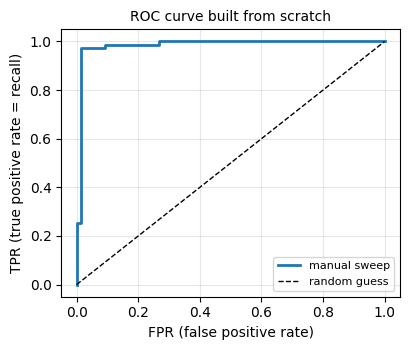

In [8]:
p_test = logit.predict_proba(scaler.transform(X_te))[:, 1]

# --- manual threshold sweep (pure numpy) ------------------------------------
thresholds = np.concatenate([[np.inf], np.sort(np.unique(p_test))[::-1]])
n_pos = int((y_te == 1).sum())
n_neg = int((y_te == 0).sum())

tprs, fprs = [], []
for t in thresholds:
    hit = p_test >= t
    tprs.append(np.sum(hit & (y_te == 1)) / n_pos)   # TPR at this threshold
    fprs.append(np.sum(hit & (y_te == 0)) / n_neg)   # FPR at this threshold
tpr = np.array(tprs)
fpr = np.array(fprs)

# NOTE: sweep starts at threshold=+inf (nobody positive -> (0,0)) and ends at
# the smallest score (everybody positive -> (1,1)).
# TIP: every unique score as a threshold => every ROC vertex is included.
print("sweep points:", len(thresholds),
      "| first (fpr,tpr):", (round(float(fpr[0]), 3), round(float(tpr[0]), 3)),
      "| last:", (round(float(fpr[-1]), 3), round(float(tpr[-1]), 3)))

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.plot(fpr, tpr, lw=2, label="manual sweep")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
ax.set_xlabel("FPR (false positive rate)")
ax.set_ylabel("TPR (true positive rate = recall)")
ax.set_title("ROC curve built from scratch", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### `roc_curve()` / `roc_auc_score()`
**What they do:** `roc_curve` returns every operating point of the threshold
sweep; `roc_auc_score` returns the trapezoidal area (AUC).
**Syntax:** `roc_curve(y_true, y_score, pos_label=None, drop_intermediate=True)` ·
`roc_auc_score(y_true, y_score)`
**Parameters:**
- `y_true` — binary labels
- `y_score` — **scores**, not hard labels: probabilities or `decision_function` output
- `drop_intermediate` — (`roc_curve` only) skip collinear points for a shorter curve
**Returns:** `(fpr, tpr, thresholds)` · a float in [0, 1]

In [9]:
fsk, tsk, thr = roc_curve(y_te, p_test)

# evaluate MY sweep at sklearn's thresholds -> must agree exactly
check = []
for t in thr:
    hit = p_test >= t
    check.append((np.sum(hit & (y_te == 0)) / n_neg, np.sum(hit & (y_te == 1)) / n_pos))
check = np.array(check)

print("max |ΔFPR| =", np.abs(check[:, 0] - fsk).max())
print("max |ΔTPR| =", np.abs(check[:, 1] - tsk).max())
print("AUC manual  :", np.trapezoid(tpr, fpr))
print("AUC sklearn :", roc_auc_score(y_te, p_test))
print("sklearn keeps", len(fsk), "vertices; my sweep keeps all", len(thresholds))


max |ΔFPR| = 0.0
max |ΔTPR| = 0.0
AUC manual  : 0.9856
AUC sklearn : 0.9856
sklearn keeps 10 vertices; my sweep keeps all 151


In [10]:
# --- AUC = P(random positive outranks random negative): Monte-Carlo check ----
rng = np.random.default_rng(SEED)
pos_scores = p_test[y_te == 1]
neg_scores = p_test[y_te == 0]
i = rng.integers(0, len(pos_scores), 20000)
j = rng.integers(0, len(neg_scores), 20000)
empirical = np.mean(pos_scores[i] > neg_scores[j])
print(f"P(positive > negative) ≈ {empirical:.4f}   |   AUC = {roc_auc_score(y_te, p_test):.4f}")


P(positive > negative) ≈ 0.9864   |   AUC = 0.9856


### ROC on imbalanced data + the Precision-Recall alternative

With 95 % negatives the FPR denominator is huge, so the ROC curve looks
flattering even for mediocre models. The **Precision-Recall curve** has no
true-negative term at all — its baseline is the *prevalence* (5 % here), so
it exposes how badly a model does on the minority class.

**Prefer the PR curve when:** the positive class is rare (fraud, disease,
churn) **or** you care about FP/FN costs.
**Prefer ROC when:** classes are roughly balanced and you care about overall
ranking quality.

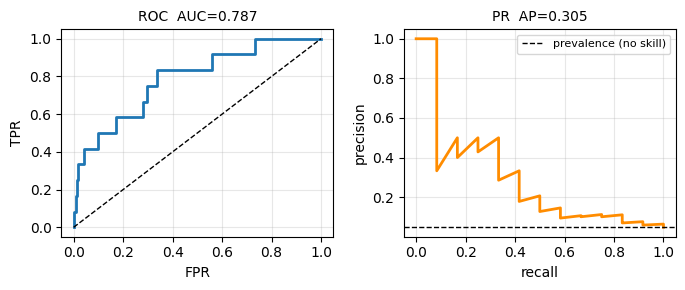

ROC-AUC = 0.787   <- looks great
PR-AUC (AP) = 0.305   <- honest: baseline is only 0.05


In [11]:
pipe_imb = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)
).fit(Xi_tr, yi_tr)
p_imb = pipe_imb.predict_proba(Xi_te)[:, 1]

f_imb, t_imb, _ = roc_curve(yi_te, p_imb)
prec, rec, _ = precision_recall_curve(yi_te, p_imb)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].plot(f_imb, t_imb, lw=2)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title(f"ROC  AUC={roc_auc_score(yi_te, p_imb):.3f}", fontsize=10)
axes[0].set_xlabel("FPR"), axes[0].set_ylabel("TPR"), axes[0].grid(alpha=0.3)

axes[1].plot(rec, prec, lw=2, color="darkorange")
axes[1].axhline(yi_te.mean(), color="k", ls="--", lw=1, label="prevalence (no skill)")
axes[1].set_title(f"PR  AP={average_precision_score(yi_te, p_imb):.3f}", fontsize=10)
axes[1].set_xlabel("recall"), axes[1].set_ylabel("precision")
axes[1].legend(fontsize=8), axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC = {roc_auc_score(yi_te, p_imb):.3f}   <- looks great")
print(f"PR-AUC (AP) = {average_precision_score(yi_te, p_imb):.3f}"
      f"   <- honest: baseline is only {yi_te.mean():.2f}")


**Section notes — ROC / PR:**

| Function | Returns |
|---|---|
| `roc_curve(y, scores)` | `fpr, tpr, thresholds` |
| `roc_auc_score(y, scores)` | AUC (threshold-free, ranking based) |
| `precision_recall_curve(y, scores)` | `precision, recall, thresholds` |
| `average_precision_score(y, scores)` | area under the PR curve |

> **Gotcha:** ROC/PR need **scores** (`predict_proba[:, 1]` or
> `decision_function`). Feeding `predict()` output gives a single useless
> operating point instead of a curve.

---
## 4. KNN — K Nearest Neighbors

▶ #166 What is K Nearest Neighbors?: https://www.youtube.com/watch?v=abnL_GUGub4
▶ #168 Session on Advanced KNN: https://www.youtube.com/watch?v=d7xo69q-1H4

**Intuition:** a *lazy learner* / *instance-based* method — it stores the
whole training set and learns nothing at prediction time. "You are the five
people you hang out with the most."

**Algorithm**
1. For a query $x$, compute the distance to every training point.
2. Sort and keep the `k` smallest.
3. Vote: `predict` = majority class among the k neighbours
   (weighted vote = sum of `1/distance` weights).
4. `predict_proba` = fraction of the k neighbours per class.

**Distance metrics** (`KNeighborsClassifier(metric=..., p=...)`)

| Metric | Formula | `metric=` value | Use when |
|---|---|---|---|
| Euclidean | $\sqrt{\sum_i (x_i-y_i)^2}$ | `"euclidean"` (default, `p=2`) | continuous features |
| Manhattan | $\sum_i \|x_i-y_i\|$ | `"manhattan"` (`p=1`) | grid-like data / outliers |
| Minkowski | $(\sum_i\|x_i-y_i\|^p)^{1/p}$ | `"minkowski", p=` | the general family (p=1,2 are above) |
| Hamming | fraction of differing entries | `"hamming"` | categorical / boolean features |

**Choosing k** — rule of thumb: use an **odd k for binary** problems so the
vote cannot tie.

| k | Behaviour |
|---|---|
| small (1, 3) | wiggly boundary, low bias / high variance → **overfits** (memorises noise) |
| large (30, 50+) | nearly a global majority vote → **underfit** |
| "right" k | validation accuracy plateaus; $\sqrt{n}$ is a starting guess |

best test accuracy at k=7: 0.953 (train 0.944)


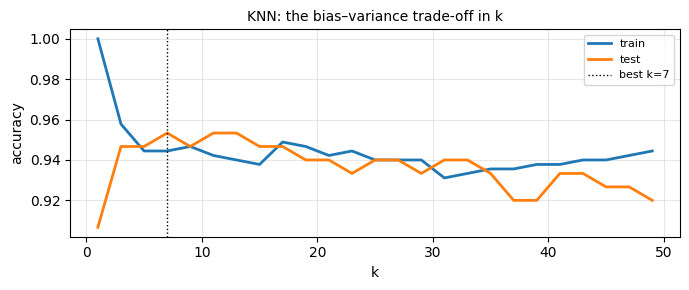

In [12]:
# --- accuracy vs k (odd values only, on the moons split) ---------------------
ks = list(range(1, 50, 2))
train_acc, test_acc = [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr)
    train_acc.append(m.score(Xm_tr, ym_tr))
    test_acc.append(m.score(Xm_te, ym_te))

best_k = ks[int(np.argmax(test_acc))]
print(f"best test accuracy at k={best_k}: {max(test_acc):.3f} "
      f"(train {train_acc[ks.index(best_k)]:.3f})")

plt.figure(figsize=(7, 3))
plt.plot(ks, train_acc, label="train", lw=2)
plt.plot(ks, test_acc, label="test", lw=2)
plt.axvline(best_k, color="k", ls=":", lw=1, label=f"best k={best_k}")
plt.xlabel("k"), plt.ylabel("accuracy")
plt.title("KNN: the bias–variance trade-off in k", fontsize=10)
plt.legend(fontsize=8), plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# NOTE: k=1 gives train accuracy 1.0 (pure memorisation); test accuracy then
# dips and wobbles as k grows.


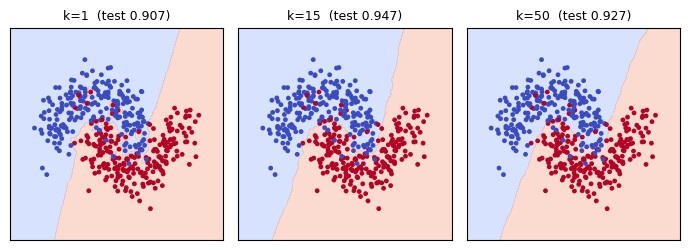

In [13]:
# --- decision boundary for k = 1 / 15 / 50 ----------------------------------
def plot_boundary(est, X, y, ax, title="", pad=0.6, grid=200):
    """Draw a 2-D classifier's decision surface."""
    x0, x1 = X[:, 0].min() - pad, X[:, 0].max() + pad
    y0, y1 = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x0, x1, grid), np.linspace(y0, y1, grid))
    Z = est.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.35, cmap="coolwarm", levels=1)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, edgecolors="none")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]), ax.set_yticks([])


fig, axes = plt.subplots(1, 3, figsize=(7, 2.6))
for ax, k in zip(axes, [1, 15, 50]):
    est = KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr)
    plot_boundary(est, Xm_tr, ym_tr, ax, f"k={k}  (test {est.score(Xm_te, ym_te):.3f})")
plt.tight_layout()
plt.show()
# TIP: k=1 carves islands around every noisy point; k=50 washes the moons out.


In [14]:
# --- weighted voting: weights="distance" ------------------------------------
for w in ["uniform", "distance"]:
    m = KNeighborsClassifier(n_neighbors=15, weights=w).fit(Xm_tr, ym_tr)
    print(f"weights={w:9s} train={m.score(Xm_tr, ym_tr):.3f}  "
          f"test={m.score(Xm_te, ym_te):.3f}")
# NOTE: distance weighting lets one close neighbour beat three far ones —
# useful when point density varies across the plane.


weights=uniform   train=0.938  test=0.947
weights=distance  train=1.000  test=0.947


### Build vs predict complexity (`algorithm=`)

| `algorithm=` | build (`fit`) | predict per query | best when |
|---|---|---|---|
| `"brute"` | $O(1)$ (just stores data) | $O(nd)$ — scan everything | $n$ small, or $d$ huge |
| `"kd_tree"` | $O(n\log n)$ | $O(\log n)$ average | $d \lesssim 10$, axis-aligned features |
| `"ball_tree"` | $O(n\log n)$ | $O(\log n)$ average | moderate $d$, non-Euclidean metrics |
| `"auto"` | picks one for you | — | default |

Trees only pay off in **low dimensions** — in high $d$ every query degenerates
into a full scan and the tree's constant factors make it *slower* than brute
force. Note the asymmetry: with brute force, `fit` is free and `predict` is
expensive (the opposite of every other model in this notebook).

In [15]:
from time import perf_counter

X_big, y_big = make_classification(
    n_samples=4000, n_features=20, n_informative=15, random_state=SEED
)
query = X_big[:500]

print(f"{'algorithm':10s} {'fit + predict (s)':>18s} {'test acc':>9s}")
for alg in ["brute", "kd_tree", "ball_tree"]:
    t0 = perf_counter()
    m = KNeighborsClassifier(n_neighbors=15, algorithm=alg).fit(X_big, y_big)
    acc = m.score(query, y_big[:500])
    print(f"{alg:10s} {perf_counter() - t0:18.3f} {acc:9.3f}")


algorithm   fit + predict (s)  test acc
brute                   0.061     0.968
kd_tree                 0.026     0.968
ball_tree               0.021     0.968


### `KNeighborsClassifier(n_neighbors=5, weights='uniform', algorithm='auto', p=2, metric='minkowski')`
**What it does:** predicts by majority vote of the k nearest training points.
**Parameters:**
- `n_neighbors` — k (odd avoids ties in binary problems)
- `weights` — `"uniform"` (equal votes) or `"distance"` (weight = 1/d)
- `algorithm` — `"auto" | "brute" | "kd_tree" | "ball_tree"` — affects *speed*, never the predictions
- `metric`, `p` — distance family; `p=1` Manhattan, `p=2` Euclidean
**Returns:** fitted estimator with `.predict`, `.predict_proba`, `.kneighbors`

In [16]:
# --- KNN from scratch in NumPy, verified against sklearn ---------------------
def knn_predict(X_train, y_train, X_query, k=5, weighted=False):
    """Euclidean KNN + majority (or 1/d weighted) vote."""
    # (n_train, n_query) pairwise euclidean distances
    d = np.sqrt(((X_train[:, None, :] - X_query[None, :, :]) ** 2).sum(-1))
    nn = np.argsort(d, axis=0)[:k]                 # k nearest indices per query
    d_k = np.take_along_axis(d, nn, axis=0)        # their distances
    labels = y_train[nn]                           # shape (k, n_query)

    out = np.empty(X_query.shape[0], dtype=int)
    for j in range(X_query.shape[0]):
        if weighted:
            w = 1.0 / (d_k[:, j] + 1e-12)          # distance weighting
            scores = np.bincount(labels[:, j], weights=w, minlength=2)
            out[j] = np.argmax(scores)
        else:
            vals, cnt = np.unique(labels[:, j], return_counts=True)
            out[j] = vals[np.argmax(cnt)]          # majority vote (ties -> smaller class)
    return out


print(f"{'k':>4} {'my acc':>9} {'sklearn acc':>12} {'identical':>10}")
for k in [1, 5, 15, 31]:
    mine = knn_predict(Xm_tr, ym_tr, Xm_te, k=k)
    theirs = KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr).predict(Xm_te)
    print(f"{k:>4} {(mine == ym_te).mean():9.4f} {(theirs == ym_te).mean():12.4f}"
          f" {np.array_equal(mine, theirs)!s:>10}")

mine_w = knn_predict(Xm_tr, ym_tr, Xm_te, k=15, weighted=True)
theirs_w = KNeighborsClassifier(15, weights="distance").fit(Xm_tr, ym_tr).predict(Xm_te)
print("weighted vote identical to sklearn:", np.array_equal(mine_w, theirs_w))


   k    my acc  sklearn acc  identical
   1    0.9067       0.9067       True
   5    0.9467       0.9467       True
  15    0.9467       0.9467       True
  31    0.9400       0.9400       True
weighted vote identical to sklearn: True


### Preprocessing gotcha — KNN is scale-dependent

Distance is computed **feature by feature**. A feature spanning
$[0, 10^4]$ dominates a feature spanning $[0, 1]$ no matter how informative
either one is.

In [17]:
rng = np.random.default_rng(SEED)
X_scale = np.column_stack([rng.normal(0, 1, 300), rng.uniform(0, 10000, 300)])
y_scale = (X_scale[:, 0] > 0).astype(int)      # the label depends ONLY on feature 0
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(
    X_scale, y_scale, test_size=0.25, random_state=SEED, stratify=y_scale
)

raw_acc = KNeighborsClassifier(5).fit(Xs_tr, ys_tr).score(Xs_te, ys_te)
sc = StandardScaler().fit(Xs_tr)
fixed_acc = (KNeighborsClassifier(5)
             .fit(sc.transform(Xs_tr), ys_tr)
             .score(sc.transform(Xs_te), ys_te))
print(f"unscaled KNN accuracy: {raw_acc:.3f}   (garbage — the [0,10000] noise feature wins)")
print(f"scaled   KNN accuracy: {fixed_acc:.3f}   (StandardScaler rescued it)")
# NOTE: the scaler is fit on TRAIN only, then reused for test — never refit on
# the combined data (that would leak test statistics).


unscaled KNN accuracy: 0.533   (garbage — the [0,10000] noise feature wins)
scaled   KNN accuracy: 0.973   (StandardScaler rescued it)


**Section notes — KNN:**

| Topic | Answer |
|---|---|
| learning type | lazy / instance-based — `fit` stores, `predict` computes |
| complexity | brute $O(nd)$ per query; trees $O(\log n)$ but only in low $d$ |
| k choice | odd for binary; small ⇒ overfit, large ⇒ underfit |
| weights | `weights="distance"` → closer neighbours count more |
| scaling | mandatory (distance-based model) |
| cost profile | expensive prediction, free training |

> **Gotcha:** the **curse of dimensionality** kills KNN: as $d$ grows, the
> gap between the nearest and the farthest point vanishes, so "nearest"
> stops meaning anything. Fixes (PCA, feature selection) are covered in
> `12_ml_dimensionality_model_selection.ipynb`.

---
## 5. Naive Bayes

▶ #192 Session 1 on Naive Bayes: https://www.youtube.com/watch?v=mEjGU4e-WPs
▶ #191 Session 2 on Naive Bayes: https://www.youtube.com/watch?v=mrBut7CPCxE
▶ #193 Session 3 on Naive Bayes: https://www.youtube.com/watch?v=_x61Lut84zI

### Bayes' rule refresher

$$P(A\mid B) = \frac{P(B\mid A)\,P(A)}{P(B)} \qquad\Longleftrightarrow\qquad
\underbrace{P(y\mid x)}_{\text{posterior}} =
\frac{\overbrace{P(x\mid y)}^{\text{likelihood}}\cdot
\overbrace{P(y)}^{\text{prior}}}{\underbrace{P(x)}_{\text{evidence}}}$$

For classification we do not need $P(x)$ (it is a constant across classes):
$\hat y = \arg\max_y P(x\mid y)P(y)$.

### Why "naive"?

The features are assumed **conditionally independent** given the class:

$$P(x_1,\dots,x_d\mid y) = \prod_{i=1}^{d} P(x_i\mid y)$$

Words in a sentence obviously are not independent ("free money" ≠ "free" +
"money" separately) — yet the argmax is often right, because NB only needs
the *ranking* of the posteriors to survive the violated assumption.

### Laplace / additive smoothing ($\alpha$)

A single zero count makes $P=0$ and the whole product collapses to 0. Fix:
add $\alpha$ to every count before normalising.

$$P(x_i\mid y) = \frac{c_{i,y}+\alpha}{\sum_j c_{j,y}+\alpha d}$$

In [18]:
# 0-count problem on a hand-built table
counts = np.array([[3, 0, 1],      # class 0 word counts:  w0 w1 w2
                   [0, 2, 5]])     # class 1 word counts


def log_likelihood(counts, alpha):
    smooth = counts + alpha
    with np.errstate(divide="ignore"):
        return np.log(smooth / smooth.sum(axis=1, keepdims=True))


ll0 = log_likelihood(counts, alpha=0)      # raw maximum-likelihood estimates
ll1 = log_likelihood(counts, alpha=1)      # Laplace smoothing (sklearn default)

print("alpha = 0 (MLE):\n", np.round(ll0, 3))
print("\nalpha = 1 (Laplace):\n", np.round(ll1, 3))

doc_words = np.array([0, 1, 2])            # a document using all three words
for name, ll in [("alpha=0", ll0), ("alpha=1", ll1)]:
    joint = ll[:, doc_words].sum(axis=1)
    bits = [f"class {c}: {'-inf (unseen word)' if not np.isfinite(v) else round(float(v), 3)}"
            for c, v in enumerate(joint)]
    print(f"{name}  log P(doc | class) -> " + " | ".join(bits))


alpha = 0 (MLE):
 [[-0.288   -inf -1.386]
 [  -inf -1.253 -0.336]]

alpha = 1 (Laplace):
 [[-0.56  -1.946 -1.253]
 [-2.303 -1.204 -0.511]]
alpha=0  log P(doc | class) -> class 0: -inf (unseen word) | class 1: -inf (unseen word)
alpha=1  log P(doc | class) -> class 0: -3.758 | class 1: -4.017


In [19]:
# --- GaussianNB: assumes x_i | y ~ Normal(mu_iy, sigma_iy^2) ----------------
gnb = GaussianNB().fit(X_tr, y_tr)
print("class priors_   :", np.round(gnb.class_prior_, 3))
print("theta_ (means)  :\n", np.round(gnb.theta_, 3))
print("var_ (variances):\n", np.round(gnb.var_, 3))
print("train / test accuracy:", round(gnb.score(X_tr, y_tr), 4), "/",
      round(gnb.score(X_te, y_te), 4))
print("predict_proba first 3 rows:\n", np.round(gnb.predict_proba(X_te)[:3], 4))

# manual joint log-likelihood for one sample: log prior + sum of Gaussian log-pdf
x0 = X_te[0]
manual = []
for c in range(len(gnb.classes_)):
    ll = (-0.5 * np.sum(np.log(2 * np.pi * gnb.var_[c]))
          - 0.5 * np.sum((x0 - gnb.theta_[c]) ** 2 / gnb.var_[c]))
    manual.append(np.log(gnb.class_prior_[c]) + ll)
print("\nmanual   _joint_log_likelihood:", np.round(manual, 6))
print("sklearn  _joint_log_likelihood:",
      np.round(gnb._joint_log_likelihood(X_te[:1])[0], 6))  # needs a 2-D input
# NOTE: GaussianNB needs NO scaling — every feature gets its own Gaussian,
# so a per-feature rescaling is absorbed into (mu, sigma).


class priors_   : [0.502 0.498]
theta_ (means)  :
 [[ 1.405 -1.349]
 [ 1.287  1.302]]
var_ (variances):
 [[0.592 1.3  ]
 [0.317 0.474]]
train / test accuracy: 0.9511 / 0.94
predict_proba first 3 rows:
 [[0.0228 0.9772]
 [0.9989 0.0011]
 [0.0244 0.9756]]

manual   _joint_log_likelihood: [-5.981727 -2.221916]
sklearn  _joint_log_likelihood: [-5.981727 -2.221916]


### `MultinomialNB(alpha=1.0)` — word counts & text classification

**What it does:** models $P(x_i\mid y)$ from *counts* — the classic
bag-of-words spam filter.
**Parameters:**
- `alpha` — Laplace smoothing (default 1.0; `alpha=0` = pure MLE → zero-count trap)
- `fit_prior` — learn $P(y)$ from data (default `True`)
- `binarize` — not used here (that is `BernoulliNB`'s parameter)
**Returns:** `.predict`, `.predict_proba`, `.feature_log_prob_`
  (log of the smoothed per-class word distributions)

In [20]:
docs = [
    "win a free lottery prize now", "free money offer click here now",
    "claim your free cash reward", "winner you won the lottery jackpot",
    "cheap meds free delivery", "limited offer win free gift",
    "meeting agenda for tomorrow", "please review the attached report",
    "lunch at the cafeteria today", "project deadline is next monday",
    "can we reschedule the standup", "the quarterly numbers look good",
    "team offsite photos from friday", "invoice for the cloud servers",
]
y_text = np.array([1] * 6 + [0] * 8)          # 1 = spam, 0 = ham

vec = CountVectorizer(stop_words="english")
X_text = vec.fit_transform(docs)
vocab = vec.get_feature_names_out()
print("docs:", X_text.shape[0], "| vocab size:", len(vocab))

mnb = MultinomialNB().fit(X_text, y_text)
new = vec.transform(["free lottery win now", "review the quarterly report"])
print("predictions (1=spam):", mnb.predict(new))
print("probabilities:\n", np.round(mnb.predict_proba(new), 4))

print("\nlog P(word | class) for 5 vocab words:\n",
      np.round(mnb.feature_log_prob_[:, :5], 3))
print("smoothing kept every word probability > 0:",
      bool(np.all(np.exp(mnb.feature_log_prob_) > 0)))
# NOTE: fit the vectorizer on TRAIN text only in real pipelines (here the toy
# corpus is small enough to show the whole flow in one cell).


docs: 14 | vocab size: 43
predictions (1=spam): [1 0]
probabilities:
 [[0.0241 0.9759]
 [0.9143 0.0857]]

log P(word | class) for 5 vocab words:
 [[-3.526 -3.526 -3.526 -4.22  -4.22 ]
 [-4.22  -4.22  -4.22  -3.526 -3.526]]
smoothing kept every word probability > 0: True


In [21]:
# --- BernoulliNB: binary (0/1) features -------------------------------------
rng = np.random.default_rng(SEED)
X_bern = rng.integers(0, 2, size=(400, 12))
y_bern = ((X_bern[:, 0] + X_bern[:, 3] + X_bern[:, 7]) >= 2).astype(int)

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    X_bern, y_bern, test_size=0.25, random_state=SEED, stratify=y_bern
)
bnb = BernoulliNB().fit(Xb_tr, yb_tr)
print("BernoulliNB test accuracy:", round(bnb.score(Xb_te, yb_te), 3))
print("P(feature=1 | class) =\n", np.round(np.exp(bnb.feature_log_prob_), 3))
# NOTE: BernoulliNB has a `binarize=` threshold (default 0.0), so it can also
# swallow continuous data by binarising it on the fly.


BernoulliNB test accuracy: 1.0
P(feature=1 | class) =
 [[0.333 0.503 0.503 0.235 0.549 0.477 0.451 0.216 0.49  0.516 0.418 0.49 ]
 [0.762 0.483 0.483 0.735 0.444 0.464 0.51  0.742 0.536 0.497 0.45  0.517]]


In [22]:
# --- when does NB shine? one honest failure ---------------------------------
print("GaussianNB on moons (non-linear, correlated features):",
      round(GaussianNB().fit(Xm_tr, ym_tr).score(Xm_te, ym_te), 3), "<- assumption violated")
print("GaussianNB on the linearly-separable binary set     :",
      round(GaussianNB().fit(X_tr, y_tr).score(X_te, y_te), 3), "<- assumptions are cheap here")


GaussianNB on moons (non-linear, correlated features): 0.853 <- assumption violated
GaussianNB on the linearly-separable binary set     : 0.94 <- assumptions are cheap here


**Section notes — Naive Bayes:**

| Variant | Assumes about $x_i\mid y$ | Typical input | Typical use |
|---|---|---|---|
| `GaussianNB` | normal, per-feature $\mu,\sigma$ | continuous | quick baseline, small tabular data |
| `MultinomialNB` | counts from a multinomial | non-negative counts | text / bag-of-words |
| `BernoulliNB` | binary 0/1 presence | booleans (or binarised) | short texts, presence-only features |

| Pros | Cons |
|---|---|
| one-pass training, $O(nd)$ | conditional independence rarely holds |
| excellent in very high $d$ (text) | probabilities are over-confident / poorly calibrated |
| works with tiny data | correlated features get double-counted |
| interpretable via `feature_log_prob_` | one unseen word without smoothing → $-\infty$ |

> **Gotcha:** "assumption violated" ≠ "model useless". NB only needs the
> **ordering** of $P(y\mid x)$ to be right; GaussianNB's decision boundary is
> linear, so it behaves like a robust linear classifier.

---
## 6. Maximum Likelihood Estimation (MLE)

▶ #196 Session on Maximum Likelihood Estimation: https://www.youtube.com/watch?v=YSur3ESoV_U

### Likelihood vs probability

- **Probability** $P(x\mid\theta)$: distribution over the data for a *fixed*
  $\theta$; sums to 1 over $x$.
- **Likelihood** $L(\theta\mid x) = P(x\mid\theta)$: a function of the
  *parameters* for fixed data; it does **not** sum to 1 over $\theta$.

**MLE** picks $\hat\theta = \arg\max_\theta L(\theta\mid x)$.

### Why the log?

i.i.d. data ⇒ $L(\theta)=\prod_i p(x_i\mid\theta)$ — a product of many small
numbers (guaranteed underflow). `log` converts products to sums, is monotonic
(so the argmax does not move) and gives much nicer gradients:

$$\ell(\theta) = \sum_i \log p(x_i\mid\theta) \qquad
\hat\theta = \arg\max \ell(\theta) = \arg\min -\ell(\theta)$$

### MLE for a Bernoulli

$p(x_i\mid p)=p^{x_i}(1-p)^{1-x_i}$ ⇒
$\ell(p) = (\sum x_i)\log p + (n-\sum x_i)\log(1-p)$.
Setting $\frac{d\ell}{dp}=0$ gives the unsurprising

$$\hat p = \frac{\#\text{successes}}{n} = \bar x$$

In [23]:
# --- Bernoulli MLE: closed form vs numerical optimisation -------------------
rng = np.random.default_rng(SEED)
x_bern = rng.binomial(n=1, p=0.7, size=60)          # 60 coin flips, true p = 0.7


def neg_log_lik_bernoulli(p, x):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return -np.sum(x * np.log(p) + (1 - x) * np.log(1 - p))


p_closed = x_bern.mean()                              # successes / n
res = minimize(lambda th: neg_log_lik_bernoulli(th[0], x_bern),
               x0=[0.5], method="L-BFGS-B", bounds=[(1e-6, 1 - 1e-6)])

print("successes / n  (closed form):", round(p_closed, 6))
print("scipy minimize (numerical)  :", round(float(res.x[0]), 6))
print("true p                      : 0.7")
print("agreement |Δ|               :", abs(p_closed - float(res.x[0])))
print("neg-log-lik at the optimum  :", round(float(res.fun), 4))


successes / n  (closed form): 0.65
scipy minimize (numerical)  : 0.65
true p                      : 0.7
agreement |Δ|               : 4.2738590444457714e-11
neg-log-lik at the optimum  : 38.8468


### MLE for a Gaussian

$$\ell(\mu,\sigma^2)= -\frac{n}{2}\log(2\pi\sigma^2)
- \frac{1}{2\sigma^2}\sum_i (x_i-\mu)^2
\;\Longrightarrow\;
\hat\mu = \bar x,\qquad \hat\sigma^2_{\text{MLE}} = \frac1n\sum_i (x_i-\bar x)^2$$

Note $\hat\sigma^2_{\text{MLE}}$ divides by **n**, not $n-1$ — MLE is
(slightly) **biased** for the variance; the unbiased estimator divides by
`n-1`, which is `np.var(x, ddof=1)`.

In [24]:
x_norm = rng.normal(loc=5.0, scale=2.0, size=200)     # true mu = 5, sigma = 2


def neg_log_lik_gauss(theta, x):
    """theta = [mu, log_sigma]; log_sigma keeps sigma > 0 automatically."""
    mu, log_sigma = theta
    sigma = np.exp(log_sigma)
    return np.sum(0.5 * np.log(2 * np.pi * sigma ** 2) + (x - mu) ** 2 / (2 * sigma ** 2))


mu_hat = x_norm.mean()
var_mle = np.mean((x_norm - mu_hat) ** 2)             # divides by n
var_unbiased = np.var(x_norm, ddof=1)                 # divides by n-1

res_g = minimize(neg_log_lik_gauss, x0=[0.0, 0.0], args=(x_norm,), method="L-BFGS-B")

print(f"{'':14s} closed form   scipy minimize     truth")
print(f"{'mu':14s} {mu_hat:12.6f} {res_g.x[0]:17.6f} {5.0:9.3f}")
print(f"{'sigma':14s} {np.sqrt(var_mle):12.6f} {np.exp(res_g.x[1]):17.6f} {2.0:9.3f}")
print(f"{'variance':14s} {var_mle:12.6f} {np.exp(2 * res_g.x[1]):17.6f} {4.0:9.3f}")
print(f"unbiased variance (ddof=1): {var_unbiased:.6f}  ==  MLE * n/(n-1) = "
      f"{var_mle * len(x_norm) / (len(x_norm) - 1):.6f}")
# TIP: optimising over log_sigma instead of sigma enforces sigma > 0 — the
# re-parameterisation trick used all over probabilistic ML.


               closed form   scipy minimize     truth
mu                 4.853285          4.853286     5.000
sigma              1.950123          1.950123     2.000
variance           3.802979          3.802979     4.000
unbiased variance (ddof=1): 3.822089  ==  MLE * n/(n-1) = 3.822089


In [25]:
# --- one tidy comparison table ----------------------------------------------
summary = pd.DataFrame(
    {
        "Bernoulli p": [x_bern.mean(), float(res.x[0]), 0.7],
        "Gaussian mu": [x_norm.mean(), float(res_g.x[0]), 5.0],
        "Gaussian sigma": [np.sqrt(var_mle), float(np.exp(res_g.x[1])), 2.0],
    },
    index=["closed form (MLE)", "scipy.optimize.minimize", "true value"],
)
print(summary.round(6))


                         Bernoulli p  Gaussian mu  Gaussian sigma
closed form (MLE)               0.65     4.853285        1.950123
scipy.optimize.minimize         0.65     4.853286        1.950123
true value                      0.70     5.000000        2.000000


### MAP vs MLE — the one-liner that explains regularization

$$\hat\theta_{\text{MAP}} = \arg\max_\theta P(\theta\mid x)
= \arg\max_\theta \big[\underbrace{\log P(x\mid\theta)}_{\text{data fit = MLE}}
+ \underbrace{\log P(\theta)}_{\text{prior}}\big]$$

- **MLE** = MAP with a flat prior ("every parameter equally likely").
- **MAP with a Gaussian prior** on the weights adds $\lambda\|w\|^2$ to the
  loss ⇒ **L2 regularization**; a Laplace prior ⇒ L1 (lasso).
- In logistic regression `C = 1/λ` — the same knob, turned the other way.

**Section notes — MLE:**

| Task | Closed form | Numerical |
|---|---|---|
| Bernoulli $p$ | $\bar x$ | `minimize` on $-\ell(p)$ |
| Gaussian $\mu$ | $\bar x$ | `minimize` on $-\ell(\mu,\log\sigma)$ |
| Gaussian $\sigma^2$ | $\frac1n\sum_i(x_i-\bar x)^2$ | same call |
| anything else | rarely exists | gradient descent / scipy / EM |

> **Gotcha:** maximise the **log**-likelihood, never the raw likelihood —
> 1000 multiplications of 0.001 underflow to 0, while their logs sum to −6908.

---
## 7. Logistic Regression

▶ #194 Session 1 on Logistic Regression: https://www.youtube.com/watch?v=BuAp03q5GAw
▶ #197 Session 3 on Logistic Regression: https://www.youtube.com/watch?v=u2IfZX5q2jY

### Why not plain linear regression for classification?

Fit `y ∈ {0,1}` with least squares and the fitted line outputs $\hat y \in
(-\infty, \infty)$ — it happily predicts −0.4 or 1.7 (impossible labels), the
residuals form two stripes, and squared error has no probability
interpretation. We need a link that squashes $w\cdot x+b$ into $(0,1)$:
the **sigmoid**.

### The sigmoid

$$\sigma(z) = \frac{1}{1+e^{-z}} \qquad
\sigma'(z) = \sigma(z)\big(1-\sigma(z)\big) \qquad
\sigma(0)=0.5,\;\; \lim_{z\to\pm\infty}\sigma(z) = 1, 0$$

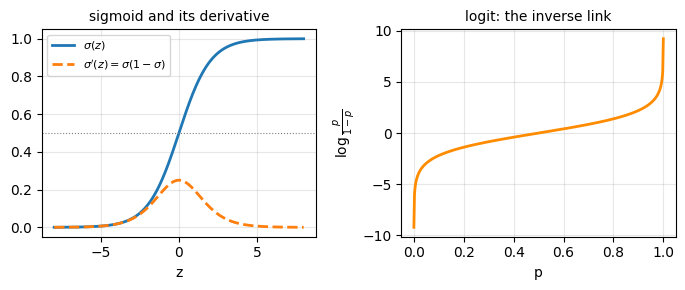

sigma(0) = 0.5 | sigma(5) = 0.99331 | sigma(-5) = 0.00669
p=0.8 -> odds = 4.0 | log-odds (logit) = 1.3863


In [26]:
z = np.linspace(-8, 8, 400)
sig = 1 / (1 + np.exp(-z))

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].plot(z, sig, lw=2, label=r"$\sigma(z)$")
axes[0].plot(z, sig * (1 - sig), lw=2, ls="--", label=r"$\sigma'(z)=\sigma(1-\sigma)$")
axes[0].axhline(0.5, color="grey", lw=0.8, ls=":")
axes[0].set_xlabel("z"), axes[0].set_title("sigmoid and its derivative", fontsize=10)
axes[0].legend(fontsize=8), axes[0].grid(alpha=0.3)

p = np.linspace(1e-4, 1 - 1e-4, 400)
axes[1].plot(p, np.log(p / (1 - p)), lw=2, color="darkorange")
axes[1].set_xlabel("p"), axes[1].set_ylabel(r"$\log\frac{p}{1-p}$")
axes[1].set_title("logit: the inverse link", fontsize=10), axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("sigma(0) =", 1 / (1 + np.exp(0)),
      "| sigma(5) =", round(1 / (1 + np.exp(-5)), 5),
      "| sigma(-5) =", round(1 / (1 + np.exp(5)), 5))
print("p=0.8 -> odds =", round(0.8 / 0.2, 3), "| log-odds (logit) =", round(np.log(0.8 / 0.2), 4))
# NOTE: log-odds = ln(p/(1-p)); one unit of w·x multiplies the ODDS by exp(w).


### Binary cross-entropy (log loss) — derivation sketch

Model: $\hat p = P(y=1\mid x) = \sigma(w\cdot x + b)$. Writing the Bernoulli
likelihood of one row and taking the negative log:

$$-\log P(y\mid x) = -\big[y\log\hat p + (1-y)\log(1-\hat p)\big]$$

Averaging over $n$ rows gives the loss that logistic regression minimises:

$$\mathcal{L}(w) = -\frac1n\sum_{i=1}^{n}\big[y_i\log\hat p_i
+ (1-y_i)\log(1-\hat p_i)\big]$$

Properties that make it the right loss:
- convex in $w$ → gradient descent reaches the **global** optimum,
- **asymmetric & unbounded**: being confidently wrong costs
  $-\log(10^{-6}) \approx 13.8$ per row while being right costs ~0,
- gradient collapses to $\nabla_w \mathcal{L} = \frac1n X^\top(\hat p - y)$.

In [27]:
p_hat = logit.predict_proba(scaler.transform(X_te))[:, 1]

eps = 1e-12
bce_manual = -np.mean(y_te * np.log(p_hat + eps) + (1 - y_te) * np.log(1 - p_hat + eps))
print("manual cross-entropy :", bce_manual)
print("sklearn log_loss     :", log_loss(y_te, p_hat))

print("confidently correct: -log(0.999999) = %.6f" % -np.log(0.999999))
print("confidently WRONG  : -log(0.000001) = %.4f" % -np.log(0.000001))
print("barely right       : -log(0.51)     = %.4f" % -np.log(0.51))


manual cross-entropy : 0.12504344060397973
sklearn log_loss     : 0.12504344060551192
confidently correct: -log(0.999999) = 0.000001
confidently WRONG  : -log(0.000001) = 13.8155
barely right       : -log(0.51)     = 0.6733


### `LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=100, multi_class='deprecated')`
**What it does:** fits $P(y=1\mid x)=\sigma(w\cdot x+b)$ by minimising
cross-entropy plus a regularization term.
**Parameters:**
- `penalty` — `"l2"` (default), `"l1"`, `"elasticnet"`, `None`
- `C` — **inverse** regularization strength: `C = 1/λ`. Small C ⇒ strong shrinkage
- `solver` — `"lbfgs"` (default, L2), `"liblinear"` (small data, l1),
  `"saga"` (large/sparse, elasticnet), `"newton-cg"`, `"sag"`
- `max_iter` — gradient iterations; raise it when you see `ConvergenceWarning`
- `multi_class` — **deprecated in 1.5**; ≥3 classes + `lbfgs` ⇒ multinomial (softmax) automatically
**Returns:** `.coef_`, `.intercept_`, `.n_iter_`, `.predict`, `.predict_proba`, `.decision_function`

In [28]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, random_state=SEED))
pipe.fit(X_tr, y_tr)
lr = pipe.named_steps["logisticregression"]

print("test accuracy:", round(pipe.score(X_te, y_te), 4),
      "| AUC:", round(roc_auc_score(y_te, pipe.predict_proba(X_te)[:, 1]), 4))
print("coef_:", np.round(lr.coef_, 3), "| intercept_:", np.round(lr.intercept_, 3))
print("n_iter_:", lr.n_iter_)
# NOTE: features are standardised, so each coefficient means "per 1 SD of x".
# WARNING: without scaling, lbfgs may need max_iter=1000+ and the coefficients
# are not comparable across features (different units).


test accuracy: 0.9667 | AUC: 0.9856
coef_: [[-1.738  4.215]] | intercept_: [-0.397]
n_iter_: [7]


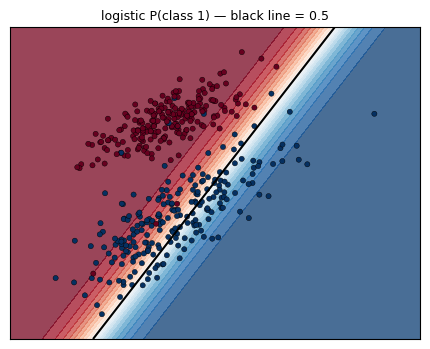

In [29]:
# --- decision boundary via predict_proba + contour --------------------------
def contour_boundary(est, X, y, ax, title="", grid=200, scaler=None):
    """Contour the predicted probability of class 1 over 2-D space."""
    x0, x1 = X[:, 0].min() - 0.7, X[:, 0].max() + 0.7
    y0, y1 = X[:, 1].min() - 0.7, X[:, 1].max() + 0.7
    xx, yy = np.meshgrid(np.linspace(x0, x1, grid), np.linspace(y0, y1, grid))
    grid_X = np.c_[xx.ravel(), yy.ravel()]
    if scaler is not None:
        grid_X = scaler.transform(grid_X)
    zz = est.predict_proba(grid_X)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap="RdBu_r", alpha=0.75)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=1.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", s=14,
               edgecolors="k", linewidths=0.3)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]), ax.set_yticks([])


fig, ax = plt.subplots(figsize=(4.4, 3.6))
contour_boundary(pipe, X_tr, y_tr, ax, "logistic P(class 1) — black line = 0.5",
                 scaler=scaler)
plt.tight_layout()
plt.show()


### Threshold tuning — the 0.3 / 0.5 / 0.7 demo

In [30]:
proba = pipe.predict_proba(X_te)[:, 1]
rows = []
for t in [0.3, 0.5, 0.7]:
    p_t = (proba >= t).astype(int)
    rows.append(dict(
        threshold=t,
        accuracy=accuracy_score(y_te, p_t),
        precision=precision_score(y_te, p_t, zero_division=0),
        recall=recall_score(y_te, p_t, zero_division=0),
        f1=f1_score(y_te, p_t, zero_division=0),
        predicted_positives=int(p_t.sum()),
    ))
print(pd.DataFrame(rows).set_index("threshold").round(4))
# NOTE: as the threshold rises, recall falls and precision rises — the same
# monotone trade-off you walk along when you move on the ROC / PR curve.


           accuracy  precision  recall      f1  predicted_positives
threshold                                                          
0.3          0.9467     0.9241  0.9733  0.9481                   79
0.5          0.9667     0.9605  0.9733  0.9669                   76
0.7          0.9800     0.9865  0.9733  0.9799                   74


In [31]:
# --- coefficient interpretation: the odds ratio -----------------------------
coefs = pd.DataFrame(
    {
        "coef": lr.coef_.ravel(),
        "odds ratio exp(coef)": np.exp(lr.coef_.ravel()),
    },
    index=[f"x{i}" for i in range(X_tr.shape[1])],
)
print(coefs.round(4))
print("\nInterpretation: +1 SD of x0 multiplies the odds of class 1 by exp(coef_).")


      coef  odds ratio exp(coef)
x0 -1.7376                0.1759
x1  4.2152               67.7045

Interpretation: +1 SD of x0 multiplies the odds of class 1 by exp(coef_).


### Regularization in logistic regression — `C` gotcha

$$\min_w \underbrace{-\ell(w)}_{\text{log loss}} + \frac{1}{2C}\|w\|^2
\qquad\Longleftrightarrow\qquad C = \frac1\lambda$$

> **Gotcha:** `C` is the **inverse** of the ridge/lasso strength λ.
> Big `C` = *weak* regularization = fit the training data harder.
> Opposite convention from `Ridge(alpha=λ)` — a classic interview trap.

In [32]:
rows = []
for C in [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]:
    m = make_pipeline(
        StandardScaler(), LogisticRegression(C=C, max_iter=1000, random_state=SEED)
    ).fit(X_tr, y_tr)
    w = m.named_steps["logisticregression"].coef_.ravel()
    rows.append(dict(C=C, lambda_=1 / C, l2_norm=np.linalg.norm(w),
                     train_acc=m.score(X_tr, y_tr), test_acc=m.score(X_te, y_te)))
print(pd.DataFrame(rows).set_index("C").round(4))
# NOTE: C grows -> ||w|| grows (less shrinkage) -> training accuracy saturates.


         lambda_  l2_norm  train_acc  test_acc
C                                             
0.001    1000.00   0.1673     0.9578    0.9533
0.010     100.00   0.9836     0.9667    0.9600
0.100      10.00   2.6971     0.9733    0.9667
1.000       1.00   4.5592     0.9756    0.9667
10.000      0.10   5.4709     0.9756    0.9667
100.000     0.01   5.6400     0.9756    0.9667


### Separated data → the coefficients blow up

If the classes are **perfectly separable**, the maximum-likelihood solution
has $\|w\|\to\infty$ (you can always push the sigmoid a little further towards
0/1). The log-likelihood has no finite optimum — only the regularizer holds
the coefficients back. Symptoms: `coef_` keeps growing with `C`, `n_iter_`
rises, and `predict_proba` saturates to 0.000/1.000 — **overconfident,
uncalibrated probabilities** even when every prediction is right.

In [33]:
X_sep, y_sep = make_blobs(n_samples=240, centers=[(-3, -3), (3, 3)],
                          cluster_std=1.3, random_state=SEED)

rows = []
for C in [0.01, 1.0, 1e6]:
    m = LogisticRegression(C=C, max_iter=2000, random_state=SEED).fit(X_sep, y_sep)
    p_sep = m.predict_proba(X_sep)[:, 1]
    rows.append(dict(C=C, coef_norm=np.linalg.norm(m.coef_), n_iter=int(m.n_iter_[0]),
                     train_acc=m.score(X_sep, y_sep),
                     log_loss=log_loss(y_sep, p_sep),
                     min_proba=p_sep.min()))
print(pd.DataFrame(rows).set_index("C").round(6))
print("\naccuracy is pinned at 1.0 from C=1 onwards while the coefficient norm")
print("keeps growing (0.63 -> 11.2, ~17x): the growth only saturates the")
print("probabilities (min_proba -> 0), it buys no extra correct predictions.")


            coef_norm  n_iter  train_acc  log_loss  min_proba
C                                                            
0.01         0.634816      10        1.0  0.085691   0.014675
1.00         1.863314      10        1.0  0.006797   0.000005
1000000.00  11.180427      14        1.0  0.000140   0.000000

accuracy is pinned at 1.0 from C=1 onwards while the coefficient norm
keeps growing (0.63 -> 11.2, ~17x): the growth only saturates the
probabilities (min_proba -> 0), it buys no extra correct predictions.


**Section notes — logistic regression:**

| Piece | Formula / knob |
|---|---|
| link | $\hat p = \sigma(w\cdot x+b)$ |
| loss | binary cross-entropy = negative log-likelihood |
| optimiser | convex ⇒ lbfgs/sag/newton all reach the global optimum |
| regularization | `C = 1/λ`, `penalty='l2'` default |
| threshold | default 0.5 — tune for the recall/precision balance |
| coefficients | `exp(coef_)` = odds ratio (on scaled features) |
| multiclass | ≥3 classes ⇒ softmax (see §8) |

> **Gotcha:** perfectly separable data ⇒ $\hat w$ diverges. Regularize
> (small `C`) or accept meaningless probabilities.

---
## 8. Softmax regression (multiclass logistic)

▶ #195 Session on Softmax Regression (Multiclass): https://www.youtube.com/watch?v=Dg-1TuPxElw

### From sigmoid to softmax

Sigmoid squashes *one* number into $(0,1)$. For K classes we need K numbers
that **sum to 1** — exponentiate the logits and normalise (after subtracting
the max for numerical stability):

$$P(y=k\mid x) = \frac{e^{z_k - \max_j z_j}}{\sum_{j=1}^{K} e^{z_j - \max_j z_j}},
\qquad z = Wx + b$$

Subtracting $\max_j z_j$ changes nothing mathematically but stops
`np.exp(1000)` from overflowing to `inf/inf = nan`.

### One-vs-Rest vs softmax (multinomial)

| | One-vs-Rest | Softmax / multinomial |
|---|---|---|
| models trained | K independent binary logistic regressions | one model with K weight vectors |
| probabilities | each in (0,1), **do not sum to 1** | sum to 1 by construction |
| objective | maximise each class vs "the rest" | single cross-entropy over all classes |
| cost | K fits | 1 fit (usually faster, joint boundary) |
| decision regions | can be inconsistent / leave gaps | globally consistent simplex |

In [34]:
# --- numerically stable softmax, from scratch -------------------------------
def softmax(Z):
    Zs = Z - Z.max(axis=1, keepdims=True)      # stabilise
    e = np.exp(Zs)
    return e / e.sum(axis=1, keepdims=True)    # rows sum to 1


def cross_entropy(P, Y):
    return -np.sum(Y * np.log(P + 1e-12)) / len(Y)


rng = np.random.default_rng(SEED)
Z = rng.normal(size=(6, 3))                       # raw scores (logits)
Y = np.zeros((6, 3))
Y[np.arange(6), rng.integers(0, 3, size=6)] = 1   # one-hot labels

P = softmax(Z)
print("softmax rows:\n", np.round(P, 4))
print("row sums:", np.round(P.sum(axis=1), 12))
print("extreme logits [1000, 1001, 1002] ->",
      np.round(softmax(np.array([[1000.0, 1001.0, 1002.0]])), 4))
print("loss:", round(cross_entropy(P, Y), 6))


softmax rows:
 [[0.3543 0.0923 0.5533]
 [0.8608 0.0478 0.0914]
 [0.3989 0.2559 0.3452]
 [0.085  0.4807 0.4343]
 [0.1857 0.5368 0.2775]
 [0.188  0.6419 0.1702]]
row sums: [1. 1. 1. 1. 1. 1.]
extreme logits [1000, 1001, 1002] -> [[0.09   0.2447 0.6652]]
loss: 1.348381


In [35]:
# --- gradient of softmax + cross-entropy (with a numeric check) -------------
def ce_grad(Z, Y):
    """d/dZ of mean cross-entropy(softmax(Z), Y) = (softmax(Z) - Y) / n."""
    return (softmax(Z) - Y) / len(Y)


g_ana = ce_grad(Z, Y)
eps = 1e-6
g_num = np.zeros_like(Z)
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        Zp, Zm = Z.copy(), Z.copy()
        Zp[i, j] += eps
        Zm[i, j] -= eps
        g_num[i, j] = (cross_entropy(softmax(Zp), Y)
                       - cross_entropy(softmax(Zm), Y)) / (2 * eps)

print("max |analytic - numeric gradient| =", np.abs(g_ana - g_num).max())
# NOTE: this is exactly the gradient gradient descent follows in softmax
# regression — the whole update is  W -= lr * X.T @ (P - Y) / n.


max |analytic - numeric gradient| = 1.565825247240582e-10


### `LogisticRegression(solver='lbfgs')` on 3 classes

sklearn ≥ 1.5 deprecates the `multi_class` parameter: with **lbfgs** and more
than 2 classes it picks the **multinomial (softmax)** objective automatically.
`solver='liblinear'` still trains one-vs-rest models under the hood.

In [36]:
softmax_model = make_pipeline(
    StandardScaler(), LogisticRegression(solver="lbfgs", max_iter=1000, random_state=SEED)
).fit(Xu_tr, yu_tr)
lr_multi = softmax_model.named_steps["logisticregression"]

proba_multi = softmax_model.predict_proba(Xu_te)
pred_multi = softmax_model.predict(Xu_te)

print("coef_ shape (K x d):", lr_multi.coef_.shape,
      "| intercept_:", np.round(lr_multi.intercept_, 3))
print("test accuracy:", round(softmax_model.score(Xu_te, yu_te), 4))
print("probabilities sum to 1 on every row:",
      bool(np.allclose(proba_multi.sum(axis=1), 1.0)))
print("argmax(predict_proba) == predict:",
      bool(np.array_equal(pred_multi, proba_multi.argmax(axis=1))))
print("\nfirst 5 probability rows:\n", np.round(proba_multi[:5], 4))


coef_ shape (K x d): (3, 2) | intercept_: [ 0.254 -0.64   0.386]
test accuracy: 0.9667
probabilities sum to 1 on every row: True
argmax(predict_proba) == predict: True

first 5 probability rows:
 [[0.0541 0.0597 0.8862]
 [0.0155 0.0031 0.9814]
 [0.0706 0.6918 0.2376]
 [0.0119 0.9796 0.0085]
 [0.0013 0.997  0.0018]]


### OvR probabilities vs softmax probabilities

A hand-rolled OvR trains K independent binary models, each answering
"class c or not?" — the K outputs are **not normalised**, so the row sums
wander around 1 (argmax still works). sklearn's `OneVsRestClassifier`
normalises them for you; softmax is the only formulation that is
*generative-ly consistent* — its rows sum to 1 by construction.

In [37]:
ovr = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=SEED)),
).fit(Xu_tr, yu_tr)
ovr_proba = ovr.predict_proba(Xu_te)

# hand-rolled OvR: K independent binary logistic regressions, no normalisation
raw_rows = []
for c in range(len(np.unique(yu_tr))):
    binary = (yu_tr == c).astype(int)
    m = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=500, random_state=SEED)).fit(Xu_tr, binary)
    raw_rows.append(m.predict_proba(Xu_te)[:, 1])
raw_ovr = np.array(raw_rows).T

print("hand-rolled OvR row sums (need NOT be 1):", np.round(raw_ovr.sum(axis=1)[:5], 3))
print("sklearn OvR row sums (it normalises)    :", np.round(ovr_proba.sum(axis=1)[:5], 3))
print("softmax row sums (by construction)      :", np.round(proba_multi.sum(axis=1)[:5], 3))
print("\nhand-rolled OvR argmax accuracy:", round((raw_ovr.argmax(axis=1) == yu_te).mean(), 4),
      "| sklearn OvR:", round(ovr.score(Xu_te, yu_te), 4),
      "| softmax:", round(softmax_model.score(Xu_te, yu_te), 4))


hand-rolled OvR row sums (need NOT be 1): [0.94  1.022 0.887 1.026 1.018]
sklearn OvR row sums (it normalises)    : [1. 1. 1. 1. 1.]
softmax row sums (by construction)      : [1. 1. 1. 1. 1.]

hand-rolled OvR argmax accuracy: 0.9667 | sklearn OvR: 0.9667 | softmax: 0.9667


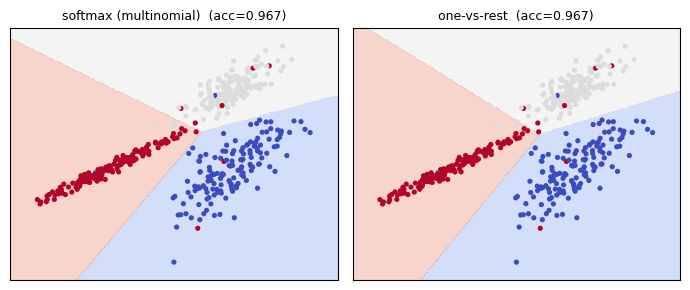

In [38]:
# --- decision regions for the 3-class model ---------------------------------
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, (mdl, t) in zip(axes, [(softmax_model, "softmax (multinomial)"),
                               (ovr, "one-vs-rest")]):
    x0, x1 = Xu_tr[:, 0].min() - 0.7, Xu_tr[:, 0].max() + 0.7
    y0, y1 = Xu_tr[:, 1].min() - 0.7, Xu_tr[:, 1].max() + 0.7
    xx, yy = np.meshgrid(np.linspace(x0, x1, 180), np.linspace(y0, y1, 180))
    zz = mdl.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.3, cmap="coolwarm", levels=2)
    ax.scatter(Xu_tr[:, 0], Xu_tr[:, 1], c=yu_tr, cmap="coolwarm", s=14,
               edgecolors="none")
    ax.set_title(f"{t}  (acc={mdl.score(Xu_te, yu_te):.3f})", fontsize=9)
    ax.set_xticks([]), ax.set_yticks([])
plt.tight_layout()
plt.show()


**Section notes — softmax:**

| Item | Detail |
|---|---|
| formula | $P(k\mid x)=\mathrm{softmax}(Wx+b)_k$ |
| stability | subtract `max` before `np.exp` |
| loss | multiclass cross-entropy $-\frac1n\sum_i \log P(y_i\mid x_i)$ |
| gradient | $(P - Y)/n$ — same shape as the prediction matrix |
| sklearn | `LogisticRegression(solver="lbfgs")` (auto-multinomial) |
| sanity checks | rows sum to 1 · `argmax(proba) == predict` |

> **Gotcha:** softmax rows sum to exactly 1, but the K scores are *coupled* —
> adding a class changes every other class's probability. OvR models do not
> have that problem (but they emit un-normalised probabilities).

---
## 9. SVM — hard margin

▶ #198 SVM Part 1 | Hard Margin SVM: https://www.youtube.com/watch?v=HfrKYccB2DQ

### Geometric intuition

Among all hyperplanes $w\cdot x + b = 0$ that separate the two classes, the
SVM picks the one with the **maximum margin** — the widest empty street
between the class boundaries.

| Term | Meaning |
|---|---|
| hyperplane | $f(x) = w\cdot x + b$; predicted class = `sign(f(x))` |
| **functional margin** | $y_i f(x_i)$ — positive when the point is on the correct side |
| **geometric margin** | $\dfrac{y_i f(x_i)}{\|w\|}$ — the actual distance to the hyperplane |
| support vectors | the points *on* the margin (or misclassified); they pin the hyperplane in place |

### The formal problem

Rescale $w,b$ until the closest points have functional margin exactly 1 —
then the geometric margin is $1/\|w\|$ and "maximise the margin" becomes a
clean quadratic program:

$$\min_{w,b}\ \tfrac12\|w\|^2 \qquad \text{s.t.}\quad
y_i(w\cdot x_i + b)\ \ge\ 1 \quad \forall i$$

A convex, differentiable objective with **linear** constraints — solvable in
closed form through the dual with Lagrange multipliers $\alpha_i$. The
constraints that hold with equality (the support vectors) get $\alpha_i > 0$;
every other point gets $\alpha_i = 0$ and simply does not matter.

In [39]:
# linearly separable 2-D blobs
Xb, yb = make_blobs(n_samples=240, centers=[(-2.5, -2.5), (2.5, 2.5)],
                    cluster_std=0.6, random_state=SEED)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    Xb, yb, test_size=0.3, random_state=SEED, stratify=yb
)

hard = SVC(kernel="linear", C=1000).fit(Xb_tr, yb_tr)   # huge C ≈ "allow no violations"
print("support vector indices :", hard.support_)
print("n_support_ (per class) :", hard.n_support_, "| total:", int(hard.n_support_.sum()))
print("dual_coef_ (alpha_i*y_i):", np.round(hard.dual_coef_.ravel(), 3))
print("train / test accuracy  :", round(hard.score(Xb_tr, yb_tr), 4), "/",
      round(hard.score(Xb_te, yb_te), 4))
print("intercept_:", np.round(hard.intercept_, 3), "| coef_ shape:", hard.coef_.shape)


support vector indices : [112  69 118]
n_support_ (per class) : [1 2] | total: 3
dual_coef_ (alpha_i*y_i): [-0.116  0.093  0.023]
train / test accuracy  : 1.0 / 1.0
intercept_: [-0.056] | coef_ shape: (1, 2)


3 of 3 stored rows are true support vectors
their alpha values: [0.1159 0.0931 0.0228]


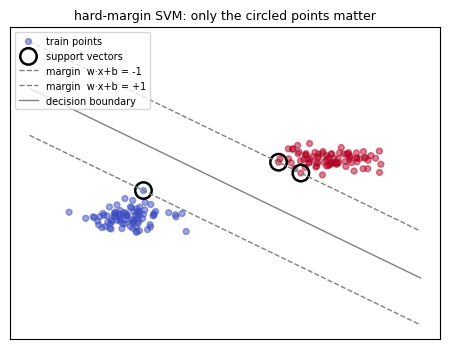

In [40]:
# --- identify support vectors: dual_coef_ != 0 ------------------------------
alpha = np.abs(hard.dual_coef_).ravel()          # |alpha_i * y_i| for each stored SV
is_sv = alpha > 1e-6                             # non-zero dual coefficient
print(f"{is_sv.sum()} of {len(hard.support_)} stored rows are true support vectors")
print("their alpha values:", np.round(alpha[is_sv], 4))

fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.scatter(Xb_tr[:, 0], Xb_tr[:, 1], c=yb_tr, cmap="coolwarm", s=18, alpha=0.5,
           label="train points")
sv_pts = hard.support_vectors_[is_sv]
ax.scatter(sv_pts[:, 0], sv_pts[:, 1], s=140, facecolors="none",
           edgecolors="k", linewidths=1.8, label="support vectors")

w = hard.coef_[0]
b = hard.intercept_[0]
x_line = np.linspace(Xb_tr[:, 0].min() - 1, Xb_tr[:, 0].max() + 1, 100)
for offset, style, lab in [(-1, "--", "margin  w·x+b = -1"), (1, "--", "margin  w·x+b = +1"),
                           (0, "-", "decision boundary")]:
    ax.plot(x_line, (offset - b - w[0] * x_line) / w[1], style, color="grey", lw=1, label=lab)
ax.set_title("hard-margin SVM: only the circled points matter", fontsize=9)
ax.legend(fontsize=7, loc="upper left")
ax.set_xticks([]), ax.set_yticks([])
plt.tight_layout()
plt.show()


In [41]:
# --- proof: retrain on ONLY the support vectors -> the same model ------------
subset = SVC(kernel="linear", C=1000).fit(Xb_tr[hard.support_], yb_tr[hard.support_])
d_full = hard.decision_function(Xb_te)
d_sub = subset.decision_function(Xb_te)
print("max |Δdecision function| :", float(np.abs(d_full - d_sub).max()))
print("identical predictions    :",
      bool(np.array_equal(hard.predict(Xb_te), subset.predict(Xb_te))))
print("retrained model also uses", int(subset.n_support_.sum()), "support vectors")
# NOTE: everything else had alpha = 0 — removing it cannot move the optimum;
# the ~1e-3 residual is just libsvm's numerical solver tolerance.
# TIP: this is why SVMs are "sparse" models and compress data so effectively.


max |Δdecision function| : 0.0013988312787762691
identical predictions    : True
retrained model also uses 3 support vectors


### Kernel trick (introduction)

A hyperplane in the *original* space is often too restrictive. Map to a
richer $\phi(x)$ where the classes become separable, run the same linear SVM
— and never compute $\phi$ explicitly, by replacing $w\cdot x$ with a
**kernel** $K(x_i, x_j) = \phi(x_i)\cdot\phi(x_j)$.
The simplest kernel is the **linear** one: $K(x_i,x_j) = x_i\cdot x_j$ —
exactly the model above.

### `SVC(kernel='linear')` vs `LinearSVC`

| | `SVC(kernel='linear')` | `LinearSVC` |
|---|---|---|
| implementation | libsvm | liblinear |
| complexity | $O(n^2\text{–}n^3)$ | $O(n\cdot d)$ — scales to big data |
| `predict_proba` | yes (with `probability=True`) | no (wrap in `CalibratedClassifierCV`) |
| extra kernels | all of them | linear only |
| `max_iter` | `-1` = unlimited (default) | **1000** → can raise `ConvergenceWarning` |

> **Gotcha:** a `ConvergenceWarning` ("LibLinear failed to converge" /
> "lbfgs failed to converge") is almost always a **scaling** problem or too
> few iterations. Fix the cause first: `StandardScaler`, then raise
> `max_iter` only if it is still needed.

In [42]:
# deliberately nasty scales: 10 of the 30 features live on a different magnitude
X_bad, y_bad = make_classification(n_samples=500, n_features=30, n_informative=20,
                                   n_redundant=5, random_state=SEED)
X_bad[:, :10] *= 1000

# record=True keeps our existing filters (matmul noise stays ignored) and only
# captures warnings that would really be shown to the user
with warnings.catch_warnings(record=True) as caught:
    raw_lr = LogisticRegression(max_iter=100, random_state=SEED).fit(X_bad, y_bad)
print("LogisticRegression UNSCALED, max_iter=100 (the default) ->",
      len(caught), "warning(s), n_iter_ =", raw_lr.n_iter_[0])
for w_ in caught:
    print("   ", str(w_.message).split("\n")[0])

with warnings.catch_warnings(record=True) as caught2:
    good_lr = make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=100, random_state=SEED))
    good_lr.fit(X_bad, y_bad)
print("after StandardScaler ->", len(caught2), "warning(s), n_iter_ =",
      good_lr.named_steps["logisticregression"].n_iter_[0])
# NOTE: same solver, same max_iter — scaling alone took it from 100 (capped,
# warning) to a handful of iterations. Always fix the cause, never just crank
# max_iter forever (that hides the problem and wastes compute).


LogisticRegression UNSCALED, max_iter=100 (the default) -> 1 warning(s), n_iter_ = 100
    lbfgs failed to converge after 100 iteration(s) (status=1):
after StandardScaler -> 0 warning(s), n_iter_ = 11


**Section notes — hard margin SVM:**

| Item | Detail |
|---|---|
| objective | $\min \tfrac12\|w\|^2$ s.t. $y_i(w\cdot x_i+b)\ge 1$ |
| margin width | $2/\|w\|$ (geometric margin $1/\|w\|$ per side) |
| support vectors | rows with `dual_coef_ != 0`; they fully determine the model |
| sparsity | retraining on SVs only reproduces the same boundary |
| linear kernel | $K(x_i,x_j)=x_i\cdot x_j$ |
| scalability | prefer `LinearSVC` for large $n$ |

> **Gotcha:** the hard margin exists **only if the data is separable**.
> One overlapping point makes the problem infeasible → §10 (soft margin).

---
## 10. SVM — soft margin

▶ #200 SVM Part 2 | Soft Margin SVM: https://www.youtube.com/watch?v=SlsXm-utgFY

### Slack variables $\xi_i \ge 0$

Real data overlaps. Let each point violate the margin by $\xi_i$ and pay for
it linearly:

$$\min_{w,b,\xi}\ \tfrac12\|w\|^2 + C\sum_{i=1}^{n}\xi_i
\qquad \text{s.t.}\quad y_i(w\cdot x_i+b)\ \ge\ 1-\xi_i$$

### The `C` parameter — misclassification tolerance

| `C` | behaviour | analogy |
|---|---|---|
| small (e.g. 0.01) | accepts many violations → **wider margin**, smoother boundary | strong regularization |
| large (e.g. 1000) | punishes every violation → **narrow margin**, fits training harder | weak regularization |

Same trade-off written unconstrained as **hinge loss**:

$$\mathcal{L} = \underbrace{\max\big(0,\ 1 - y_i f(x_i)\big)}_{\text{hinge loss}}
+ \frac{1}{2C}\|w\|^2$$

Points are sorted by how bad they are: **correct & outside the margin** →
hinge 0; **inside the margin** → hinge $\in (0,1)$; **misclassified** →
hinge $> 1$. Exactly the points with a nonzero hinge loss become support
vectors.

> **Gotcha:** `C = 1/λ` again — *small C ⇒ heavy regularization*. Same
> direction as logistic regression, opposite to `Ridge(alpha=λ)`.

In [43]:
# --- what C does to margin, support vectors and accuracy --------------------
rows = []
for C in [0.01, 0.1, 1, 10, 1000]:
    m = SVC(kernel="linear", C=C).fit(Xm_tr, ym_tr)
    rows.append(dict(C=C, n_support=int(m.n_support_.sum()),
                     train_acc=m.score(Xm_tr, ym_tr),
                     test_acc=m.score(Xm_te, ym_te)))
print(pd.DataFrame(rows).set_index("C").round(4))
# NOTE: tiny C -> many SVs (the street is so wide that most points "touch" it)
# and accuracy collapses; large C -> fewer SVs, training accuracy -> 1.


         n_support  train_acc  test_acc
C                                      
0.01           312     0.8178    0.8133
0.10           193     0.8556    0.8533
1.00           156     0.8600    0.8533
10.00          150     0.8644    0.8733
1000.00        149     0.8644    0.8733


### The kernel trick, fully

| Kernel | $K(x_i,x_j)$ | Extra knobs | Use when |
|---|---|---|---|
| `linear` | $x_i\cdot x_j$ | — | $d$ large, $n$ small (text), data already separable |
| `poly` | $(\gamma\, x_i\cdot x_j + r)^d$ | `degree`, `gamma`, `coef0` | known smooth polynomial interactions |
| `rbf` (gaussian) | $\exp(-\gamma\|x_i-x_j\|^2)$ | `gamma` | default for non-linear data, moderate $n$ |
| `sigmoid` | $\tanh(\gamma\, x_i\cdot x_j + r)$ | `gamma`, `coef0` | behaves like a 2-layer net (rarely best) |

**`gamma` = locality.** It is the inverse width of the RBF bump: large
$\gamma$ → each point's influence dies quickly → tight, wiggly islands
(overfit); small $\gamma$ → influence spreads far → smooth, almost linear
boundary (underfit). Default `gamma='scale'` $= \dfrac{1}{n_{\text{features}}\cdot \mathrm{Var}(X)}$
— one more reason to scale your data first.

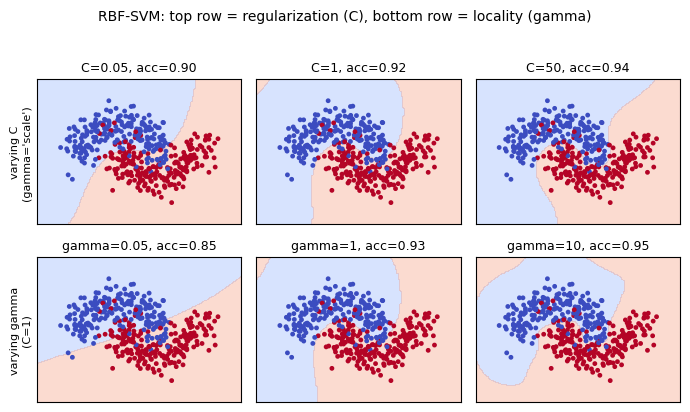

In [44]:
# --- C x gamma grid: decision boundaries ------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(7, 4))

for ax, C in zip(axes[0], [0.05, 1, 50]):
    m = SVC(kernel="rbf", C=C, gamma="scale").fit(Xm_tr, ym_tr)
    plot_boundary(m, Xm_tr, ym_tr, ax, f"C={C}, acc={m.score(Xm_te, ym_te):.2f}", grid=140)

for ax, g in zip(axes[1], [0.05, 1, 10]):
    m = SVC(kernel="rbf", C=1, gamma=g).fit(Xm_tr, ym_tr)
    plot_boundary(m, Xm_tr, ym_tr, ax, f"gamma={g}, acc={m.score(Xm_te, ym_te):.2f}", grid=140)

axes[0, 0].set_ylabel("varying C\n(gamma='scale')", fontsize=8)
axes[1, 0].set_ylabel("varying gamma\n(C=1)", fontsize=8)
plt.suptitle("RBF-SVM: top row = regularization (C), bottom row = locality (gamma)",
             fontsize=10, y=1.02)
plt.tight_layout()
plt.show()
# TIP: C and gamma are BOTH worth a GridSearchCV — they interact.


In [45]:
# --- inspecting a fitted SVC -------------------------------------------------
rbf = SVC(kernel="rbf", C=10, gamma="scale", probability=True,
          random_state=SEED).fit(Xm_tr, ym_tr)
print("support_vectors_ shape :", rbf.support_vectors_.shape)
print("n_support_ per class   :", rbf.n_support_, "| total:", int(rbf.n_support_.sum()))
print("dual_coef_ shape       :", rbf.dual_coef_.shape,
      "| range", np.round(rbf.dual_coef_.min(), 3), "to", np.round(rbf.dual_coef_.max(), 3))
print("decision_function first 5:", np.round(rbf.decision_function(Xm_te[:5]), 3))
print("predict_proba first 3 rows:\n", np.round(rbf.predict_proba(Xm_te[:3]), 4))
print("train / test accuracy  :", round(rbf.score(Xm_tr, ym_tr), 4), "/",
      round(rbf.score(Xm_te, ym_te), 4))
# NOTE: probability=True fits an internal Platt-scaling CV — hence
# random_state matters and fit gets noticeably slower.


support_vectors_ shape : (85, 2)
n_support_ per class   : [44 41] | total: 85
dual_coef_ shape       : (1, 85) | range -10.0 to 10.0
decision_function first 5: [ 1.696 -1.578  3.017  3.981 -1.432]
predict_proba first 3 rows:
 [[0.0367 0.9633]
 [0.9609 0.0391]
 [0.0028 0.9972]]
train / test accuracy  : 0.9467 / 0.9333


In [46]:
# --- kernel comparison on the same split (linear vs rbf vs poly) ------------
rows = []
for kernel, kw in [("linear", {}), ("poly", {"degree": 3}),
                   ("rbf", {}), ("sigmoid", {})]:
    m = make_pipeline(StandardScaler(),
                      SVC(kernel=kernel, random_state=SEED, **kw)).fit(Xm_tr, ym_tr)
    rows.append(dict(kernel=kernel, train_acc=m.score(Xm_tr, ym_tr),
                     test_acc=m.score(Xm_te, ym_te),
                     n_support=int(m.named_steps["svc"].n_support_.sum())))
print(pd.DataFrame(rows).set_index("kernel").round(4))


         train_acc  test_acc  n_support
kernel                                 
linear      0.8644    0.8667        152
poly        0.8511    0.8600        161
rbf         0.9200    0.9267        121
sigmoid     0.6800    0.7000        160


### SVM for regression, and the scalability caveat

**SVR** is the same machinery with a different loss: it fits a tube of width
`ε` around the data and only penalises points *outside* the tube
(`epsilon`-insensitive loss).

```python
from sklearn.svm import SVR
SVR(kernel="rbf", C=1.0, epsilon=0.1).fit(X, y)   # regressor, not classifier
```

> **Gotcha — scalability:** libsvm is $O(n^2)$–$O(n^3)$ in training time and
> stores an $n\times n$ kernel matrix. 100k rows is hopeless; for big data
> prefer `LinearSVC`/`SGDClassifier`, or use kernels on a sample.

In [47]:
# SVR one-liner on a small regression toy problem
from sklearn.svm import SVR  # noqa: F401  (imported here to keep the section self-contained)

y_reg = np.sin(np.linspace(0, 6, 120)) + rng.normal(0, 0.1, 120)
X_reg = np.linspace(0, 6, 120).reshape(-1, 1)
svr = SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_reg, y_reg)
print("SVR R^2 on the sine toy data:", round(svr.score(X_reg, y_reg), 3))


SVR R^2 on the sine toy data: 0.987


**Section notes — soft margin:**

| Item | Detail |
|---|---|
| objective | $\min \tfrac12\|w\|^2 + C\sum\xi_i$, $y_i f(x_i) \ge 1-\xi_i$ |
| loss view | hinge loss $+\ \tfrac{1}{2C}\|w\|^2$ |
| `C` | small ⇒ wide margin (many SVs), large ⇒ fit training harder |
| `gamma` | inverse locality of the RBF kernel; `scale` by default |
| kernels | `linear` / `poly` / `rbf` / `sigmoid` |
| inspection | `support_vectors_`, `n_support_`, `dual_coef_` |
| regression | `SVR(epsilon=0.1)` — tube of width ε |
| cost | training $O(n^2$–$n^3)$ — not for huge $n$ |

> **Gotcha:** `probability=True` changes nothing about the boundary — it only
> adds a post-hoc probability calibration (and a `random_state` dependency).

---
## 11. Model comparison mini-project

Same seeded moons split, five models, one table of **accuracy / F1 / AUC**,
a row of confusion matrices and a row of decision boundaries. Nothing beats
seeing them side by side.

▶ #176 Accuracy, Confusion Matrix, Type 1 & Type 2 Errors: https://www.youtube.com/watch?v=c09drtuCS3c
▶ #185 ROC Curve and AUC: https://www.youtube.com/watch?v=gdW6hj9IXaA
▶ #166 What is K Nearest Neighbors?: https://www.youtube.com/watch?v=abnL_GUGub4

               accuracy      f1     auc  log_loss
model                                            
KNN k=15         0.9467  0.9467  0.9829    0.3699
SVM (RBF)        0.9267  0.9262  0.9829    0.1802
Logistic         0.8600  0.8627  0.9381    0.3228
GaussianNB       0.8533  0.8571  0.9378    0.3396
Dummy (prior)    0.5000  0.0000  0.5000    0.6931


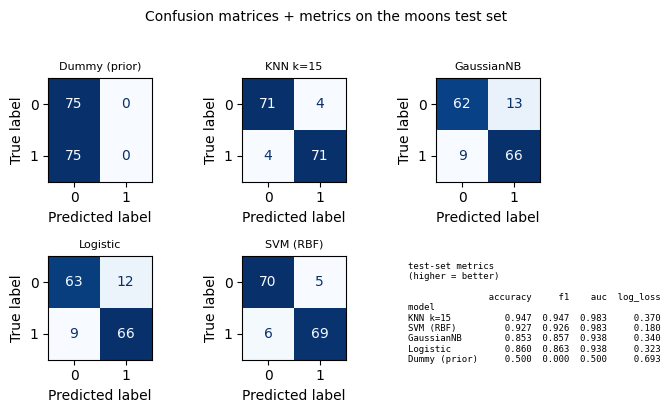

In [48]:
models = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "KNN k=15": make_pipeline(StandardScaler(),
                              KNeighborsClassifier(n_neighbors=15)),
    "GaussianNB": GaussianNB(),
    "Logistic": make_pipeline(StandardScaler(),
                              LogisticRegression(max_iter=500, random_state=SEED)),
    "SVM (RBF)": make_pipeline(StandardScaler(),
                               SVC(kernel="rbf", C=10, probability=True,
                                   random_state=SEED)),
}

fig_cm, axes_cm = plt.subplots(2, 3, figsize=(7, 4))
rows, fitted = [], {}
for ax, (name, est) in zip(axes_cm.ravel(), models.items()):
    est.fit(Xm_tr, ym_tr)
    fitted[name] = est
    proba = est.predict_proba(Xm_te)[:, 1]
    p = est.predict(Xm_te)
    rows.append(dict(model=name,
                     accuracy=accuracy_score(ym_te, p),
                     f1=f1_score(ym_te, p),
                     auc=roc_auc_score(ym_te, proba),
                     log_loss=log_loss(ym_te, proba)))
    ConfusionMatrixDisplay.from_predictions(ym_te, p, ax=ax, cmap="Blues",
                                            colorbar=False)
    ax.set_title(name, fontsize=8)

comparison = pd.DataFrame(rows).set_index("model")
print(comparison.round(4).sort_values("auc", ascending=False))

# 6th panel: print the table inside the figure
ax = axes_cm.ravel()[5]
ax.axis("off")
txt = comparison.round(3).sort_values("auc", ascending=False).to_string()
ax.text(0.0, 0.95, "test-set metrics\n(higher = better)\n\n" + txt,
        fontsize=6.5, family="monospace", va="top")
plt.suptitle("Confusion matrices + metrics on the moons test set", fontsize=10, y=1.02)
plt.tight_layout()
plt.show()


### Decision boundaries of all five models

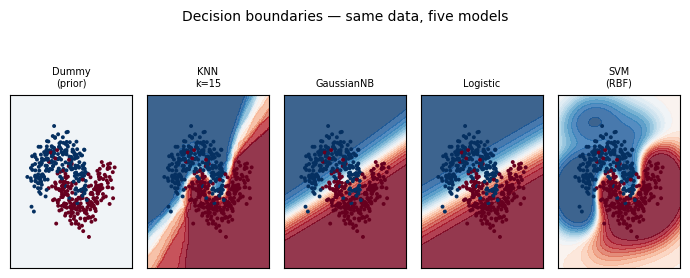

In [49]:
fig_b, axes_b = plt.subplots(1, 5, figsize=(7, 2.6))
gx, gy = np.meshgrid(np.linspace(Xm_tr[:, 0].min() - 0.8, Xm_tr[:, 0].max() + 0.8, 180),
                     np.linspace(Xm_tr[:, 1].min() - 0.8, Xm_tr[:, 1].max() + 0.8, 180))
grid = np.c_[gx.ravel(), gy.ravel()]

for ax, (name, est) in zip(axes_b, fitted.items()):
    zz = est.predict_proba(grid)[:, 1].reshape(gx.shape)
    ax.contourf(gx, gy, zz, levels=20, cmap="RdBu_r", alpha=0.8)
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=ym_tr, cmap="RdBu_r", s=8,
               edgecolors="none")
    ax.set_title(name.replace(" ", "\n"), fontsize=7)
    ax.set_xticks([]), ax.set_yticks([])
plt.suptitle("Decision boundaries — same data, five models", fontsize=10, y=1.05)
plt.tight_layout()
plt.show()


### Takeaway — model, feature and regularization trade-offs

| Model | Boundary shape | Speed | Probabilities | Wins when… |
|---|---|---|---|---|
| Dummy | none | instant | priors | you need a **baseline**; anything below it is a bug |
| KNN | data-shaped, local | slow predict | vote fractions | few dimensions, no training budget |
| GaussianNB | linear | very fast | exact-ish | high $d$, tiny data, need speed |
| Logistic | linear | fast | well-calibrated | features are informative and linearly separable |
| SVM (RBF) | smooth & curved | slow for big $n$ | calibrated post-hoc | mid-size data, clear margin structure |

**The three levers, in order of impact:**
1. **Features / representation** — no classifier rescues garbage features
   (scaling alone flipped KNN from 0.50 to 0.95 in §4).
2. **Model family** — linear vs local vs kernel: choose the boundary shape
   your data has (see the boundary row above).
3. **Regularization / hyper-parameters** — `C`, `gamma`, `k`, `α`; always via
   cross-validation on a *held-out* set, never on the test set.

> **Gotcha:** a complex model that beats the baseline by 0.5 % on one split
> is noise. Compare with cross-validation (notebook 12) before celebrating.

---
## 12. Interview Q&A sheet

**Q1. Why does KNN need scaling but GaussianNB (mostly) not?**
KNN's decision depends on raw distances — an unscaled feature with a large
range dominates the metric. GaussianNB models each feature with its own
$(\mu, \sigma)$, so a per-feature rescaling is absorbed into those
parameters and leaves the likelihood ranking unchanged.

**Q2. Precision vs recall — when do you pick which?**
Cost of **FP** high (spam filter marking real mail as spam): optimise
**precision**. Cost of **FN** high (disease missed): optimise **recall**.
You cannot maximise both — moving the threshold trades one for the other.

**Q3. When should you use the Precision-Recall curve instead of ROC?**
When the positive class is rare (few % of rows) or FP/FN costs dominate.
ROC's FPR has a huge true-negative denominator, so on 95/5 data the ROC curve
looks far too good; PR's baseline is the prevalence instead of 0.5.

**Q4. What is the "naive" assumption of Naive Bayes, and does breaking it
ruin the model?**
$P(x_1..x_d\mid y)=\prod_i P(x_i\mid y)$ (conditional independence). Breaking
it double-counts correlated evidence and the probabilities become
over-confident — but the *argmax* often still ranks classes correctly, so
accuracy survives. NB is a strong, fast baseline, not a calibrated forecaster.

**Q5. What do `C` and `gamma` mean in an SVM?**
`C` = how much you penalise margin violations: small C ⇒ wide margin, more
support vectors, smoother boundary (stronger regularization); large C ⇒ narrow
margin, fits training harder. `gamma` = locality of the RBF kernel: large
gamma ⇒ each point influences only its immediate neighbourhood (wiggly,
overfitting); small gamma ⇒ influence spreads far (smooth, underfitting).

**Q6. Log loss vs accuracy — why can a model have great accuracy and bad
log loss?**
Accuracy counts only the argmax at threshold 0.5; log loss charges for
*confidence*. A model can be right on every row with p = 0.51 (accuracy 1.0,
log loss ≈ 0.67) while another that is right with p = 0.999 gets log loss
≈ 0.001. Conversely, one confidently wrong prediction (p = 1e-6) can wreck
log loss while barely moving accuracy.

**Q7. Why can't we use plain linear regression for classification?**
Its prediction is unbounded (−0.4, 1.7 are not labels), least squares
penalises confident-but-correct predictions as hard as wrong ones, and the
residual assumptions (homoscedastic normal noise) are violated by binary
targets. The sigmoid + log loss fixes all three.

**Q8. What happens when data is perfectly separable?**
For logistic regression and soft-margin-free SVM the MLE has no finite
solution — coefficients diverge (`coef_` explodes, `n_iter_` rises,
probabilities saturate). Remedies: regularization (small `C`), or accept that
only the sign of the decision function is meaningful.

**Q9. Why do SVMs only store support vectors?**
Only the points on/violating the margin get a non-zero Lagrange multiplier
$\alpha_i$. All other points have $\alpha_i = 0$, so deleting them cannot
change the optimum (proved numerically in §9). That sparsity is also why SVMs
compress data well — and why adding useless points far from the boundary
costs nothing.

**Q10. Macro vs weighted F1 — which one do you report?**
**Macro** = unweighted mean of per-class F1 → use when every class matters
equally (rare classes must not be drowned out). **Weighted** = weighted by
`support` → use when you care about overall row-level quality. On highly
imbalanced data, weighted F1 ≈ accuracy in disguise; report both plus the
per-class table.

### Metric selection cheat sheet

| Situation | Report / optimise |
|---|---|
| imbalanced classes (any split worse than ~80/20) | **PR-AUC**, **F1**, per-class recall, balanced accuracy |
| cost of **FP** is high (spam, false alarm) | **precision** at a chosen recall, or the PR curve |
| cost of **FN** is high (disease, fraud) | **recall** at a chosen precision |
| you need well-calibrated probabilities | **log loss** (and reliability plots) |
| you need a single threshold-free ranking score, balanced data | **ROC-AUC** |
| multiclass, classes imbalanced | **macro-F1** primary, weighted-F1 secondary |
| always, first | accuracy **vs a DummyClassifier baseline** |

---
## Quick revision sheet

| Need | Reach for |
|---|---|
| one number, balanced data | `accuracy_score` |
| one number, imbalanced data | `f1_score` / `balanced_accuracy_score` / `average_precision_score` |
| where the model is wrong | `confusion_matrix` + `ConfusionMatrixDisplay` |
| per-class breakdown | `classification_report(output_dict=True)` |
| threshold-free ranking quality | `roc_auc_score`, `average_precision_score` |
| tune the operating point | `roc_curve` / `precision_recall_curve` |
| fast text baseline | `CountVectorizer` + `MultinomialNB(alpha=1)` |
| calibrated probabilities, linear boundary | `LogisticRegression` |
| K classes, one model | `LogisticRegression(solver="lbfgs")` (softmax) |
| non-linear boundary, mid-size data | `SVC(kernel="rbf", C=..., gamma=...)` |
| no training time, small data | `KNeighborsClassifier(k odd, weights="distance")` |
| scaling-first models | KNN, SVM, logistic — always `StandardScaler` |

**Formula flashcards**

- accuracy = (TP+TN)/N · precision = TP/(TP+FP) · recall = TP/(TP+FN)
- F1 = 2PR/(P+R) = 2TP/(2TP+FP+FN) · balanced acc = (recall + specificity)/2
- TPR = recall · FPR = FP/(FP+TN) · AUC = P(score⁺ > score⁻)
- sigmoid $\sigma(z)=1/(1+e^{-z})$ · logit $=\log\frac{p}{1-p}$ · odds $=\frac{p}{1-p}$
- BCE $=-\frac1n\sum[y\log\hat p+(1-y)\log(1-\hat p)]$
- softmax $=\exp(z_k)/\sum_j\exp(z_j)$ (subtract `max` first)
- SVM: $\min\frac12\|w\|^2 + C\sum\xi_i$ · hinge $=\max(0,1-yf(x))$ · margin $=2/\|w\|$
- Bayes: $P(y\mid x)\propto P(x\mid y)P(y)$ · MLE $\hat p=\bar x$, $\hat\mu=\bar x$
- regularization: `C = 1/λ` (sklearn) vs `alpha = λ` (Ridge/Lasso)

> **Interview short-list:** Type I vs Type II errors · precision vs recall ·
> why ROC lies on imbalanced data · why KNN/SVM need scaling · what `C` and
> `gamma` do · `C` vs `Ridge alpha` · why log loss beats accuracy ·
> how smoothing fixes zero counts · why only support vectors matter ·
> why perfectly separable data breaks MLE.

---
**Next notebook:** `12_ml_dimensionality_model_selection.ipynb` — the curse
of dimensionality, PCA, feature selection, cross-validation and
`GridSearchCV` (the tools that turn the comparisons in §11 into rigorous
model selection).

**Playlist:** https://www.youtube.com/playlist?list=PLKnIA16_RmvbAlyx4_rdtR66B7EHX5k3z